# Final Project: Regression and Classification Across Eight Model Families

**HCAI 4302: Fundamentals of Human-Centered AI Models**
Gemar Johnston &nbsp;|&nbsp; October 2026

---

## About this notebook

This project runs the same eight model families on two problems: predicting median house value (regression) and flagging stroke risk from symptoms (classification). Each model is judged three ways: a plain train/test split, a train/validation/test split, and 5-fold cross-validation repeated 100 times with different random splits. The repeated CV is the part I care about most, because it shows how much a model's score moves around just because of which rows landed in which fold.


**How to run it**

1. Put this notebook and the two CSV files in the same folder (`housing.csv`, `stroke_risk_dataset.csv`). If either CSV is missing, the notebook rebuilds it automatically with the generator in Section 1, so it will not crash.
2. Run all cells top to bottom (`Kernel > Restart & Run All`). The 100-repeat cross-validation is the slow part. It uses every CPU core it can find (`N_JOBS = -1`). On a single core the two repeated-CV runs took me about 26 minutes (housing) and 20 minutes (stroke), and a multi-core laptop should be much faster.
3. If you only want a fast smoke test, set `QUICK_RUN = True` in the setup cell. That drops the CV to 3 repeats. Results and plots will then be thin, so switch it back for the real thing.
4. This task is intensive and required my PC to work hard. 

**Contents**

| Section | What is in it |
|---|---|
| 0 | Setup and configuration |
| 1 | Data (synthetic, with notes on how it was built) |
| 2 | Shared evaluation machinery |
| 3 | Task 1: Regression, housing prices |
| 4 | Task 2: Classification, stroke risk |
| 5 | Notes and discoveries (complexities, traps, fail points) |
| 6 | Automated sanity checks, environment, and a closing reflection |

## Setup and configuration

Everything tunable lives in one cell. `N_REPEATS = 100` is what the assignment requires, so I left it alone.

In [ ]:
import os, sys, time, math, inspect, warnings, platform, hashlib, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from joblib import Parallel, delayed
from IPython.display import display

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                            accuracy_score, precision_score, recall_score, f1_score,
                            roc_curve, roc_auc_score)

# ---------------- configuration ----------------
SEED       = 42        # used for every model that has a random_state
N_REPEATS  = 100       # assignment: 5-fold CV repeated 100 times
N_FOLDS    = 5
N_JOBS     = -1        # -1 = use all cores
QUICK_RUN  = bool(int(os.environ.get("HCAI_QUICK_RUN", "0")))   # set True for a 3-repeat smoke test
if QUICK_RUN:
    N_REPEATS = 3
# Optional: keep finished CV blocks on disk so an interrupted run can resume instead of starting over.
# Off by default so a normal run never reads stale files. Cache entries are keyed to the data, the grid, and the seeds.
CV_CACHE   = bool(int(os.environ.get("HCAI_CV_CACHE", "0")))
CV_CACHE_DIR = "cv_cache"

# ---------------- environment guard ----------------
_sk = tuple(int(p) for p in sklearn.__version__.split(".")[:2])
assert _sk >= (1, 2), f"scikit-learn >= 1.2 required (found {sklearn.__version__})"

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 60)

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "legend.frameon": False, "font.size": 10,
})

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"N_REPEATS={N_REPEATS}, N_FOLDS={N_FOLDS}, N_JOBS={N_JOBS}, QUICK_RUN={QUICK_RUN}")

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0
N_REPEATS=100, N_FOLDS=5, N_JOBS=-1, QUICK_RUN=False


## 1. Data

**Important:** `housing.csv` and `stroke_risk_dataset.csv` are **synthetic**. I generated them for this project so the notebook is self-contained and reproducible. They imitate the *shape* of two well-known public datasets (California census housing, and a symptom-based stroke screening table) but they contain no real houses and no real patients, so none of the findings below say anything about the real world.

I did build in the kind of wrinkles real data has, because I wanted something worth checking:

- **Housing:** a categorical column (`ocean_proximity`), a handful of missing `total_bedrooms` values, a target that is top-coded at 500,001, and rooms/bedrooms/population/households that move together.
- **Stroke:** 15 binary symptoms plus age, moderately imbalanced classes, and an extra column called `Stroke Risk (%)` that the label was derived from. That column is a leakage trap, and I deal with it explicitly in Section 4.

The generator below only writes a CSV if the file is not already there.

In [2]:
def make_housing(n=1000, seed=4302):
    """Synthetic California-style housing data (NOT real census data)."""
    rng = np.random.default_rng(seed)
    # name, lat, lon, share of rows, spatial spread (deg), price multiplier, income shift
    hubs = [
        ("LA",     34.05, -118.25, 0.30, 0.30, 1.10,  0.20),
        ("SF",     37.77, -122.30, 0.20, 0.22, 1.28,  0.55),
        ("SD",     32.85, -117.10, 0.12, 0.22, 1.12,  0.10),
        ("SAC",    38.58, -121.45, 0.12, 0.28, 0.95, -0.15),
        ("FRESNO", 36.75, -119.75, 0.14, 0.35, 0.78, -0.60),
        ("IE",     34.00, -117.20, 0.12, 0.28, 0.88, -0.35),
    ]
    shares = np.array([h[3] for h in hubs])
    hub_idx = rng.choice(len(hubs), size=n, p=shares / shares.sum())

    lat = np.empty(n); lon = np.empty(n)
    mult = np.empty(n); inc_shift = np.empty(n); is_sf = np.zeros(n, bool)
    for i, h in enumerate(hub_idx):
        _, la, lo, _, sp, pm, sh = hubs[h]
        lat[i] = la + rng.normal(0, sp)
        lon[i] = lo + rng.normal(0, sp * 1.2)
        mult[i], inc_shift[i] = pm, sh
        is_sf[i] = hubs[h][0] == "SF"

    # rough coastline: (32.5N,-117.1W) -> (40N,-124.3W). Rows "in the ocean" get mirrored inland.
    coast_lon = -117.1 - 0.96 * (lat - 32.5)
    d = lon - coast_lon
    lon = np.where(d < 0, coast_lon + np.abs(d) + 0.02, lon)
    d = lon - coast_lon

    ocean = np.where(d < 0.15, "NEAR OCEAN", np.where(d < 0.55, "<1H OCEAN", "INLAND")).astype(object)
    ocean[is_sf & (d < 0.6)] = "NEAR BAY"
    coastal_premium = pd.Series(ocean).map(
        {"NEAR OCEAN": 70000, "NEAR BAY": 55000, "<1H OCEAN": 28000, "INLAND": 0}).to_numpy()

    income = np.exp(rng.normal(1.22 + inc_shift * 0.25 - 0.05 * (ocean == "INLAND"), 0.42))
    income = np.clip(income, 0.5, 15.0).round(4)

    age = np.clip(np.round(rng.normal(28, 12.5, n)), 2, 52).astype(int)
    households = np.clip(np.round(np.exp(rng.normal(5.95, 0.55, n))), 20, 3000).astype(int)
    rooms = np.round(households * np.clip(rng.normal(5.4, 1.2, n), 2.2, 12)).astype(int)
    bedrooms = np.round(rooms * np.clip(rng.normal(0.205, 0.035, n), 0.1, 0.4)).astype(int)
    population = np.round(households * np.clip(rng.normal(2.9, 0.8, n), 1.2, 8)).astype(int)

    base = 38000 + 36500 * income ** 1.08 + coastal_premium + 650 * age
    value = base * mult * np.exp(rng.normal(0, 0.17, n))
    value = np.clip(np.round(value), 15000, 500001).astype(int)  # census-style top-coding

    df = pd.DataFrame({
        "longitude": lon.round(2), "latitude": lat.round(2),
        "housing_median_age": age, "total_rooms": rooms, "total_bedrooms": bedrooms.astype(float),
        "population": population, "households": households, "median_income": income,
        "ocean_proximity": ocean, "median_house_value": value,
    })
    miss = rng.choice(n, size=int(round(0.014 * n)), replace=False)
    df.loc[miss, "total_bedrooms"] = np.nan  # a few holes, like the real thing
    return df


def make_stroke(n=1200, seed=4303):
    """Synthetic stroke-risk screening data (NOT real patient data)."""
    rng = np.random.default_rng(seed)
    age = np.clip(np.round(rng.normal(54, 16, n)), 18, 90).astype(int)
    age_s = (age - 54) / 16
    frailty = rng.normal(0, 1, n)  # hidden health factor that makes symptoms co-occur

    #            name                              base   frailty age    risk-weight
    spec = [
        ("Chest Pain",                            -1.00, 0.55, 0.35, 0.55),
        ("Shortness of Breath",                   -1.10, 0.60, 0.30, 0.60),
        ("Irregular Heartbeat",                   -1.20, 0.50, 0.40, 1.10),
        ("Fatigue & Weakness",                    -0.60, 0.50, 0.25, 0.45),
        ("Dizziness",                             -0.90, 0.45, 0.20, 0.70),
        ("Swelling (Edema)",                      -1.30, 0.50, 0.30, 0.40),
        ("Pain in Neck/Jaw/Shoulder/Back",        -1.00, 0.40, 0.20, 0.35),
        ("Excessive Sweating",                    -1.20, 0.40, 0.10, 0.25),
        ("Persistent Cough",                      -1.10, 0.35, 0.15, 0.10),
        ("Nausea/Vomiting",                       -1.30, 0.35, 0.05, 0.20),
        ("High Blood Pressure",                   -0.70, 0.60, 0.55, 1.25),
        ("Chest Discomfort (Activity)",           -1.10, 0.50, 0.30, 0.50),
        ("Cold Hands/Feet",                       -1.20, 0.30, 0.10, 0.15),
        ("Snoring/Sleep Apnea",                   -0.80, 0.40, 0.25, 0.50),
        ("Anxiety/Feeling of Doom",               -1.00, 0.30, 0.00, 0.30),
    ]
    cols, score = {}, np.zeros(n)
    for name, b0, bf, ba, w in spec:
        p = 1 / (1 + np.exp(-(b0 + bf * frailty + ba * age_s)))
        s = (rng.random(n) < p).astype(int)
        cols[name] = s
        score += w * s
    score += 0.045 * (age - 54) + rng.normal(0, 0.9, n) - 3.0
    risk_pct = np.round(100 / (1 + np.exp(-score)), 1)

    df = pd.DataFrame({"Age": age, **cols})
    df["Stroke Risk (%)"] = risk_pct
    df["At Risk (Binary)"] = (risk_pct >= 50).astype(int)
    return df

In [3]:
HOUSING_CSV = "housing.csv"
STROKE_CSV  = "stroke_risk_dataset.csv"

for fname, maker in [(HOUSING_CSV, make_housing), (STROKE_CSV, make_stroke)]:
    if os.path.exists(fname):
        print(f"found      {fname}")
    else:
        maker().to_csv(fname, index=False)
        print(f"not found, regenerated {fname}")

found      housing.csv
found      stroke_risk_dataset.csv


## 2. Shared evaluation machinery

Both tasks use the same grid of models and the same three evaluation schemes, so I wrote the machinery once and call it twice. A few design decisions that matter:

- **Scaling happens inside each fit.** The assignment says to standardize all predictors. I do, but the scaler (and the missing-value imputer, and the one-hot encoder) is fitted on *only the rows a model is allowed to train on* and then applied to the held-out rows. Scaling the whole dataset first would quietly leak test-set means and variances into training! I wanted to make sure I accounted for this. 
- **Cross-validation preprocesses once per fold**, then fits every model on that fold, which is both leakage-safe and much cheaper than rebuilding a pipeline for every single model.
- **Model selection never uses the test set.** Wherever I pick a "best" configuration, it is chosen from the CV results (training data only). Test-set numbers are reported, not optimized.
- **Convergence warnings are counted, not hidden.** They are tallied per model and reported in Section 5.

In [ ]:
# ======================================================================
# Hyperparameter grids (exactly as specified in the assignment)
# ======================================================================
LAMBDAS      = [0.1, 1, 2, 3, 4, 5]
L1_RATIOS    = [0.1, 0.3, 0.5, 0.7, 0.9]
KNN_K        = [4, 5, 6, 7]
KNN_METRICS  = ["euclidean", "manhattan", "minkowski"]
MINKOWSKI_P  = 3            # p=2 would make "minkowski" identical to "euclidean" (see Notes)
DEPTHS       = [2, 3, 4, 5, 6]
N_TREES      = [50, 100, 150]
NN_LAYERS    = [(50,), (100,), (100, 50), (50, 50)]
NN_ACTS      = ["relu", "tanh"]

FAMILIES = ["Linear", "Lasso", "Ridge", "ElasticNet", "KNN", "DecisionTree", "RandomForest", "NeuralNet"]
FAMILY_COLORS = {f: plt.cm.tab10.colors[i] for i, f in enumerate(FAMILIES)}

def build_grid():
    specs = []
    def add(family, params, label):
        specs.append({"id": len(specs), "family": family, "params": params, "label": label})
    add("Linear", {}, "Linear")
    for lam in LAMBDAS:
        add("Lasso", {"lam": lam}, f"Lasso(lam={lam})")
    for lam in LAMBDAS:
        add("Ridge", {"lam": lam}, f"Ridge(lam={lam})")
    for lam in LAMBDAS:
        for l1 in L1_RATIOS:
            add("ElasticNet", {"lam": lam, "l1": l1}, f"ElasticNet(lam={lam}, l1={l1})")
    for k in KNN_K:
        for m in KNN_METRICS:
            add("KNN", {"k": k, "metric": m}, f"KNN(k={k}, {m})")
    for d in DEPTHS:
        add("DecisionTree", {"depth": d}, f"DecisionTree(depth={d})")
    for d in DEPTHS:
        for n in N_TREES:
            add("RandomForest", {"depth": d, "trees": n}, f"RandomForest(depth={d}, trees={n})")
    for hl in NN_LAYERS:
        for act in NN_ACTS:
            add("NeuralNet", {"layers": hl, "act": act}, f"NeuralNet({'-'.join(map(str, hl))}, {act})")
    return specs

SPECS = build_grid()

# ======================================================================
# Estimator factory. Same grid for both tasks; the task decides which sklearn class is used.
# ======================================================================
_NEW_LOGIT_API = inspect.signature(LogisticRegression).parameters["penalty"].default == "deprecated"

def make_logit(l1_ratio, lam):
    """Penalised logistic regression, with C = 1/lambda. lam=None means unpenalised.
    sklearn 1.8 replaced the `penalty=` argument with `l1_ratio=`; this wrapper works on both APIs."""
    if lam is None:
        return (LogisticRegression(C=np.inf, max_iter=5000) if _NEW_LOGIT_API
                else LogisticRegression(penalty=None, max_iter=5000))
    C = 1.0 / lam
    if _NEW_LOGIT_API:
        return LogisticRegression(C=C, l1_ratio=l1_ratio, solver="lbfgs" if l1_ratio == 0 else "saga", max_iter=5000)
    if l1_ratio == 0:
        return LogisticRegression(penalty="l2", C=C, solver="lbfgs", max_iter=5000)
    if l1_ratio == 1:
        return LogisticRegression(penalty="l1", C=C, solver="saga", max_iter=5000)
    return LogisticRegression(penalty="elasticnet", C=C, l1_ratio=l1_ratio, solver="saga", max_iter=5000)

def make_estimator(task, family, p):
    reg = task == "reg"
    if family == "Linear":
        return LinearRegression() if reg else make_logit(0.0, None)
    if family == "Lasso":
        return Lasso(alpha=p["lam"], max_iter=10000) if reg else make_logit(1.0, p["lam"])
    if family == "Ridge":
        return Ridge(alpha=p["lam"]) if reg else make_logit(0.0, p["lam"])
    if family == "ElasticNet":
        return (ElasticNet(alpha=p["lam"], l1_ratio=p["l1"], max_iter=10000) if reg
                else make_logit(p["l1"], p["lam"]))
    if family == "KNN":
        kw = {"n_neighbors": p["k"], "metric": p["metric"]}
        if p["metric"] == "minkowski":
            kw["p"] = MINKOWSKI_P
        return KNeighborsRegressor(**kw) if reg else KNeighborsClassifier(**kw)
    if family == "DecisionTree":
        return (DecisionTreeRegressor(max_depth=p["depth"], random_state=SEED) if reg
                else DecisionTreeClassifier(max_depth=p["depth"], random_state=SEED))
    if family == "RandomForest":
        kw = dict(n_estimators=p["trees"], max_depth=p["depth"], random_state=SEED, n_jobs=1)
        return RandomForestRegressor(**kw) if reg else RandomForestClassifier(**kw)
    if family == "NeuralNet":
        kw = dict(hidden_layer_sizes=p["layers"], activation=p["act"], max_iter=500,
                early_stopping=True, n_iter_no_change=10, random_state=SEED)
        if reg:   # house values are ~1e5, so the network needs a scaled target to learn at all
            return TransformedTargetRegressor(regressor=MLPRegressor(**kw), transformer=StandardScaler())
        return MLPClassifier(**kw)
    raise ValueError(family)

# ======================================================================
# Preprocessing: impute -> (one-hot) -> standardize, always fitted on training rows only
# ======================================================================
def build_preprocessor(X):
    num_cols = X.select_dtypes(include="number").columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    parts = [("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                            ("scale", StandardScaler())]), num_cols)]
    if cat_cols:
        parts.append(("cat", Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                                    ("scale", StandardScaler())]), cat_cols))
    return ColumnTransformer(parts)

# ======================================================================
# Metrics
# ======================================================================
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"RMSE": float(np.sqrt(mse)), "MSE": float(mse),
            "MAE": float(mean_absolute_error(y_true, y_pred)), "R2": float(r2_score(y_true, y_pred))}

def classification_metrics(y_true, y_pred):
    return {"Accuracy": float(accuracy_score(y_true, y_pred)),
            "Precision": float(precision_score(y_true, y_pred, zero_division=0)),
            "Recall": float(recall_score(y_true, y_pred, zero_division=0)),
            "F1": float(f1_score(y_true, y_pred, zero_division=0))}

METRIC_FN    = {"reg": regression_metrics, "clf": classification_metrics}
METRIC_NAMES = {"reg": ["RMSE", "MSE", "MAE", "R2"], "clf": ["Accuracy", "Precision", "Recall", "F1"]}
PRIMARY      = {"reg": ("RMSE", False), "clf": ("F1", True)}      # (metric, higher_is_better)

def get_scores(est, X):
    return est.predict_proba(X)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(X)

def _fit_counting_warnings(est, X, y):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        est.fit(X, y)
    return sum(issubclass(item.category, ConvergenceWarning) for item in w)

# ======================================================================
# Evaluation 1 and 2: fit once on X_fit, score on one or more held-out sets
# ======================================================================
def holdout_eval(task, specs, X_fit, y_fit, eval_sets):
    prep = build_preprocessor(X_fit)
    A = prep.fit_transform(X_fit)
    E = {name: prep.transform(Xe) for name, (Xe, ye) in eval_sets.items()}
    y_fit = np.asarray(y_fit)
    rows = {name: [] for name in eval_sets}
    scores = {name: {} for name in eval_sets}
    conv = np.zeros(len(specs), dtype=int)
    for s in specs:
        est = make_estimator(task, s["family"], s["params"])
        conv[s["id"]] = _fit_counting_warnings(est, A, y_fit)
        for name, (Xe, ye) in eval_sets.items():
            rows[name].append({"id": s["id"], "model": s["label"], "family": s["family"],
                               **METRIC_FN[task](np.asarray(ye), est.predict(E[name]))})
            if task == "clf":
                scores[name][s["id"]] = get_scores(est, E[name])
    return {"metrics": {k: pd.DataFrame(v) for k, v in rows.items()}, "scores": scores, "conv": conv}

# ======================================================================
# Evaluation 3: repeated K-fold. One task = one full 5-fold pass over every configuration.
# ======================================================================
def cv_one_repeat(task, specs, X, y, repeat):
    Splitter = KFold if task == "reg" else StratifiedKFold
    splitter = Splitter(n_splits=N_FOLDS, shuffle=True, random_state=SEED + repeat)
    names = METRIC_NAMES[task]
    y = np.asarray(y)
    acc = np.zeros((len(specs), len(names)))
    conv = np.zeros(len(specs), dtype=int)
    for tr, te in splitter.split(X, y):
        prep = build_preprocessor(X)                    # fitted on this fold's training rows only
        A = prep.fit_transform(X.iloc[tr])
        B = prep.transform(X.iloc[te])
        for s in specs:
            est = make_estimator(task, s["family"], s["params"])
            conv[s["id"]] += _fit_counting_warnings(est, A, y[tr])
            m = METRIC_FN[task](y[te], est.predict(B))
            acc[s["id"]] += [m[k] for k in names]
    return acc / N_FOLDS, conv

def _cache_key(task, X, y):
    h = hashlib.md5()
    h.update(pd.util.hash_pandas_object(X, index=False).to_numpy().tobytes())
    h.update(np.asarray(y).tobytes())
    h.update(repr([(s["family"], s["params"]) for s in SPECS]).encode())
    h.update(f"{task}|{SEED}|{N_FOLDS}|{MINKOWSKI_P}|{sklearn.__version__}".encode())
    return h.hexdigest()[:12]

def run_cv(task, specs, X, y, n_repeats, block=10):
    """Returns (array[repeats, configs, metrics], convergence counts, compute seconds)."""
    key = _cache_key(task, X, y) if CV_CACHE else None
    if CV_CACHE:
        os.makedirs(CV_CACHE_DIR, exist_ok=True)
    results, compute_seconds, t_wall = [], 0.0, time.time()
    for start in range(0, n_repeats, block):
        stop = min(start + block, n_repeats)
        path = os.path.join(CV_CACHE_DIR, f"{task}_{key}_{start}_{stop}.pkl") if CV_CACHE else None
        chunk = None
        if path and os.path.exists(path):
            try:
                with open(path, "rb") as fh:
                    chunk, secs = pickle.load(fh)
                print(f"   repeats {start + 1:>3}-{stop:<3} loaded from cache", flush=True)
            except Exception:
                chunk = None
        if chunk is None:
            t0 = time.time()
            chunk = Parallel(n_jobs=N_JOBS)(delayed(cv_one_repeat)(task, specs, X, y, r) for r in range(start, stop))
            secs = time.time() - t0
            if path:
                with open(path, "wb") as fh:
                    pickle.dump((chunk, secs), fh)
            print(f"   repeats {start + 1:>3}-{stop:<3} finished   ({time.time() - t_wall:6.0f}s elapsed)", flush=True)
        results += chunk
        compute_seconds += secs
    arr = np.stack([r[0] for r in results])             # shape (repeats, configs, metrics)
    conv = np.sum([r[1] for r in results], axis=0)
    return arr, conv, compute_seconds

# ======================================================================
# Assembling and presenting results
# ======================================================================
M_TT  = "Train/Test (test set)"
M_VAL = "Train/Val/Test (validation set)"
M_TVT = "Train/Val/Test (test set)"
M_CV  = "5-fold CV x100 (mean)"
M_SD  = "5-fold CV x100 (std dev)"

def assemble(task, tt, tvt, cv_arr):
    names = METRIC_NAMES[task]
    pick = lambda df: df.set_index("id")[names]
    wide = pd.concat({M_TT: pick(tt["metrics"]["test"]),
                    M_VAL: pick(tvt["metrics"]["val"]),
                    M_TVT: pick(tvt["metrics"]["test"]),
                    M_CV: pd.DataFrame(cv_arr.mean(axis=0), columns=names),
                    M_SD: pd.DataFrame(cv_arr.std(axis=0, ddof=1), columns=names)}, axis=1)
    wide.index = [s["label"] for s in SPECS]
    wide.index.name = "model"
    return wide

def best_per_family(wide, task):
    """Positional ids of the best configuration inside each family, judged by CV only."""
    metric, higher = PRIMARY[task]
    col = wide[(M_CV, metric)].to_numpy()
    fam = np.array([s["family"] for s in SPECS])
    picks = []
    for f in FAMILIES:
        idx = np.where(fam == f)[0]
        picks.append(int(idx[np.argmax(col[idx])] if higher else idx[np.argmin(col[idx])]))
    return picks

def metric_view(wide, metric, ids=None):
    """One metric, all evaluation methods side by side (easier to read than the 20-column table)."""
    out = pd.DataFrame({m: wide[(m, metric)] for m in [M_TT, M_VAL, M_TVT, M_CV, M_SD]})
    out.columns = ["Train/Test: test", "Train/Val/Test: validation", "Train/Val/Test: test",
                "CV mean (x100)", "CV std dev"]
    return out if ids is None else out.iloc[ids]

# ======================================================================
# Plot helpers
# ======================================================================
def plot_cv_family_best(cv_arr, picks, metric_idx, metric_name, title, ylabel):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [2.4, 1]})
    x = np.arange(1, cv_arr.shape[0] + 1)
    for sid in picks:
        s = SPECS[sid]
        ax1.plot(x, cv_arr[:, sid, metric_idx], color=FAMILY_COLORS[s["family"]], lw=1.2, label=s["label"])
    ax1.set_xlabel("CV iteration (one 5-fold pass with its own random split)")
    ax1.set_ylabel(ylabel)
    ax1.set_title(title)
    ax1.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
    data = [cv_arr[:, sid, metric_idx] for sid in picks]
    bp = ax2.boxplot(data, patch_artist=True, showfliers=True, flierprops={"markersize": 3})
    for patch, sid in zip(bp["boxes"], picks):
        patch.set_facecolor(FAMILY_COLORS[SPECS[sid]["family"]]); patch.set_alpha(0.7)
    ax2.set_xticks(range(1, len(picks) + 1))
    ax2.set_xticklabels([SPECS[i]["family"] for i in picks], rotation=40, ha="right")
    ax2.set_title(f"Spread of {metric_name}\n(best config per family)")
    fig.tight_layout()
    return fig

def plot_cv_small_multiples(cv_arr, picks, metric_idx, title, ylabel):
    fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
    x = np.arange(1, cv_arr.shape[0] + 1)
    for ax, fam in zip(axes.ravel(), FAMILIES):
        ids = [s["id"] for s in SPECS if s["family"] == fam]
        for sid in ids:
            ax.plot(x, cv_arr[:, sid, metric_idx], color=FAMILY_COLORS[fam], lw=0.6, alpha=0.45)
        best = [i for i in picks if SPECS[i]["family"] == fam][0]
        ax.plot(x, cv_arr[:, best, metric_idx], color="black", lw=1.4)
        ax.set_title(f"{fam}  ({len(ids)} configs)", fontsize=10)
        ax.set_xlabel("CV iteration", fontsize=8)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel, fontsize=9)
    fig.suptitle(title + "   (black = best config per family)", fontsize=13, fontweight="bold", y=1.0)
    fig.tight_layout()
    return fig

print(f"{len(SPECS)} model configurations in the grid")
display(pd.DataFrame(SPECS).groupby("family", sort=False).size().reindex(FAMILIES).rename("configurations").to_frame().T)

83 model configurations in the grid


family,Linear,Lasso,Ridge,ElasticNet,KNN,DecisionTree,RandomForest,NeuralNet
configurations,1,6,6,30,12,5,15,8


## 3. Task 1: Regression Analysis, Housing Prices

**Goal:** Predict `median_house_value` from every other column in `housing.csv`, standardizing all predictors, and compare eight model families under three evaluation schemes (train/test, train/validation/test, 5-fold CV repeated 100 times). Metrics saved for every model: RMSE, MSE, MAE, R².

A few interpretation choices before I started:

- "Use all variables" means all nine predictors, including the categorical `ocean_proximity`. A categorical column cannot be standardized as-is, so I one-hot encode it first and then standardize the resulting columns like everything else. That gives 12 model inputs.
- `total_bedrooms` has a few blanks. I impute the median, learned from training rows only.
- The 5-fold CV runs on the **training** portion (the 80% from the first split). The test set stays untouched until the very end, which also keeps the three methods comparable. 
- Checking and validation took a large amount of time. I did not expect to have to account for the time it took!

In [ ]:
housing = pd.read_csv(HOUSING_CSV)
TARGET_H = "median_house_value"

print(f"{housing.shape[0]:,} rows x {housing.shape[1]} columns\n")
display(housing.head())

overview = pd.DataFrame({"dtype": housing.dtypes.astype(str), "missing": housing.isna().sum(),
                        "unique values": housing.nunique()})
display(overview.T)
display(housing.describe().T.round(2))

cap = housing[TARGET_H].max()
print(f"Top-coding check: {(housing[TARGET_H] == cap).mean():.1%} of rows sit exactly at the maximum value of {cap:,}.")
print(f"Missing cells overall: {int(housing.isna().sum().sum())} (all in: {', '.join(housing.columns[housing.isna().any()])})")

1,000 rows x 10 columns



,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
0,-118.37,33.94,36,1259,316.0,1024,367,2.2817,NEAR OCEAN,221533
1,-122.50,38.20,19,2115,399.0,896,355,5.3609,NEAR BAY,477897
2,-117.79,33.72,36,4928,1330.0,2144,857,4.0830,<1H OCEAN,350430
3,-121.83,37.62,52,2185,349.0,711,482,3.9661,NEAR BAY,383072
4,-121.70,38.56,8,4097,892.0,1387,783,3.0236,INLAND,170030


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,median_house_value
dtype,float64,float64,int64,int64,float64,int64,int64,float64,str,int64
missing,0,0,0,0,14,0,0,0,0,0
unique values,409,409,51,881,600,805,545,989,4,965


,count,mean,std,min,25%,50%,75%,max
longitude,1000.0,-119.13,1.84,-122.52,-121.22,-118.37,-117.60,-116.28
latitude,1000.0,35.45,2.04,32.30,33.85,34.35,37.58,39.32
housing_median_age,1000.0,28.30,12.14,2.00,20.00,29.00,37.00,52.00
total_rooms,1000.0,2421.86,1559.33,296.00,1403.50,2067.00,3026.00,15064.00
total_bedrooms,986.0,498.00,332.32,69.00,272.00,408.50,632.25,2984.00
population,1000.0,1315.30,843.82,170.00,764.50,1125.00,1633.75,7935.00
households,1000.0,452.89,266.76,78.00,276.00,396.00,566.50,2270.00
median_income,1000.0,3.66,1.68,0.91,2.51,3.32,4.40,14.69
median_house_value,1000.0,242624.50,110211.25,53228.00,157352.25,221295.00,312436.75,500001.00


Top-coding check: 3.5% of rows sit exactly at the maximum value of 500,001.
Missing cells overall: 14 (all in: total_bedrooms)


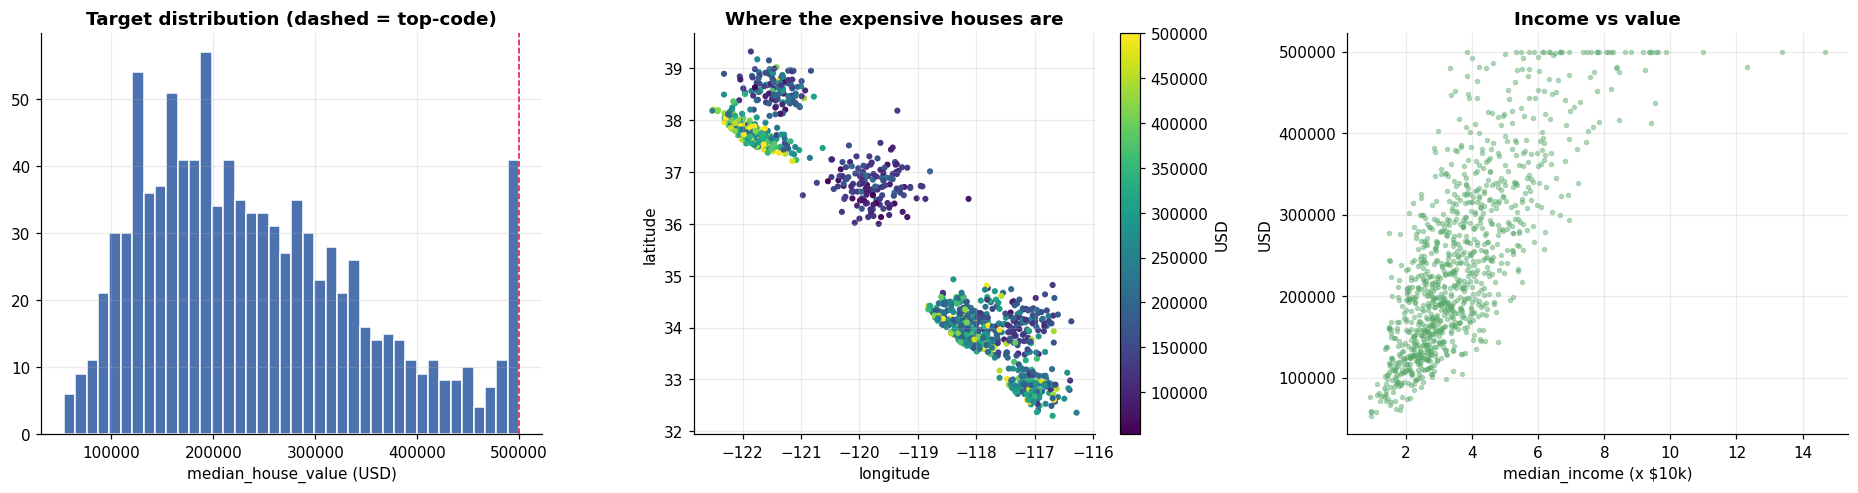

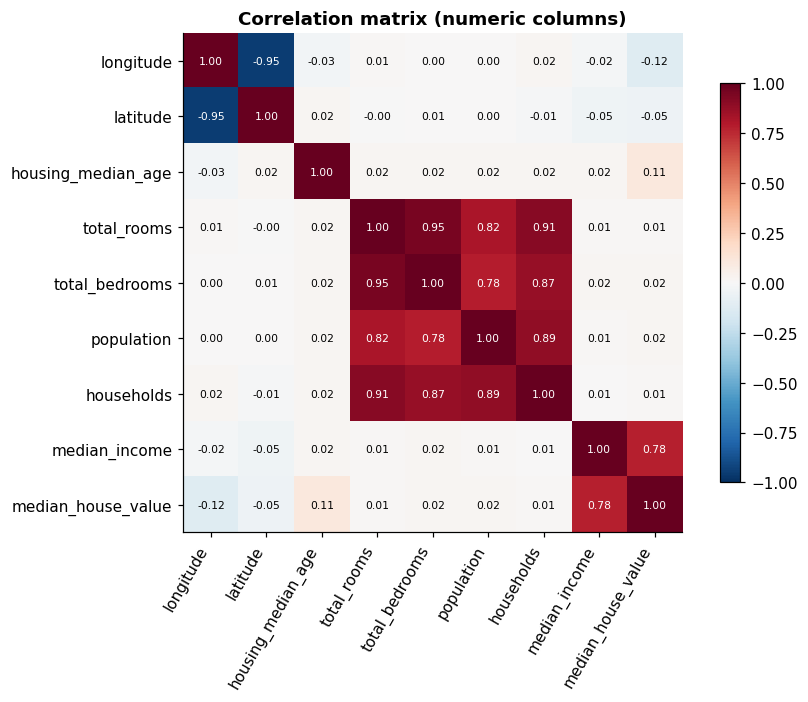

Variance inflation factors (VIF > 10 is the usual red flag):


,total_rooms,total_bedrooms,latitude,longitude,households,population,median_income,housing_median_age
VIF,14.8,10.7,10.6,10.6,9.4,4.8,1.0,1.0


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

ax[0].hist(housing[TARGET_H], bins=40, color="#4C72B0", edgecolor="white")
ax[0].axvline(cap, color="crimson", ls="--", lw=1)
ax[0].set_title("Target distribution (dashed = top-code)")
ax[0].set_xlabel("median_house_value (USD)")

sc = ax[1].scatter(housing["longitude"], housing["latitude"], c=housing[TARGET_H], s=9, cmap="viridis")
ax[1].set_title("Where the expensive houses are")
ax[1].set_xlabel("longitude"); ax[1].set_ylabel("latitude")
fig.colorbar(sc, ax=ax[1], label="USD")

ax[2].scatter(housing["median_income"], housing[TARGET_H], s=7, alpha=0.4, color="#55A868")
ax[2].set_title("Income vs value")
ax[2].set_xlabel("median_income (x $10k)"); ax[2].set_ylabel("USD")
fig.tight_layout()
plt.show()

# correlation heat map + variance inflation factors for the numeric predictors
num = housing.select_dtypes(include="number")
corr = num.corr()
fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix (numeric columns)")
fig.tight_layout()
plt.show()

preds_num = num.drop(columns=[TARGET_H]).dropna()
R = np.corrcoef(preds_num.to_numpy(), rowvar=False)
vif = pd.Series(np.diag(np.linalg.inv(R)), index=preds_num.columns, name="VIF").sort_values(ascending=False)
print("Variance inflation factors (VIF > 10 is the usual red flag):")
display(vif.round(1).to_frame().T)

**My interpretation.** The target is right-skewed with a pile-up at the top-code, which means some very expensive homes are recorded as "500,001 or more" and the true values are hidden from every model. Location carries a lot of signal (expensive coastal clusters show up clearly), and income is the strongest single numeric driver. The size columns (`total_rooms`, `total_bedrooms`, `population`, `households`) are tightly correlated with each other, and the VIF table confirms it. That is harmless for prediction accuracy but it will make individual linear coefficients unreliable, and it is the reason I kept an eye on whether Lasso and Ridge would behave any differently from plain least squares (on this grid they mostly do not, interesting to observe for me).

### 3.1 Splitting the data

The assignment prescribes the exact split calls so everyone's numbers line up. I use them as written (the PDF text has a few typos: stray spaces in `train_ test_ split` and a hyphen in `y-housing_train`; I corrected those to the clearly intended names so it did not interfere with my findings).

**Heads-up:** Task 2 reuses the names `X_train`, `X_val`, `y_train`, `y_val` for its own split, which would silently overwrite these. Nothing downstream depends on those globals, because every function takes its data as explicit arguments. It is important to always look to the future code just in case
we run into any issues. 

In [ ]:
X_housing = housing.drop(columns=[TARGET_H])
y_housing = housing[TARGET_H]

# --- the two splits, exactly as prescribed -------------------------------------------------
X_housing_train, X_housing_test, y_housing_train, y_housing_test = train_test_split(
    X_housing, y_housing, test_size=0.2, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_housing_train, y_housing_train, test_size=0.2, random_state=42)
# --------------------------------------------------------------------------------------------

print(pd.DataFrame({"rows": [len(X_train), len(X_val), len(X_housing_test), len(housing)],
                    "share": [len(X_train) / len(housing), len(X_val) / len(housing),
                            len(X_housing_test) / len(housing), 1.0]},
                index=["train (fit)", "validation", "test (held out)", "total"]).round(3))

# Standardization sanity check: scaler learns from training rows only
prep_demo = build_preprocessor(X_housing_train)
Z_tr = prep_demo.fit_transform(X_housing_train)
Z_te = prep_demo.transform(X_housing_test)
print(f"\nModel inputs after encoding: {Z_tr.shape[1]} columns")
print(f"Training columns:  largest |mean| = {np.abs(Z_tr.mean(axis=0)).max():.1e},  std range = {Z_tr.std(axis=0).min():.3f} to {Z_tr.std(axis=0).max():.3f}")
print(f"Test columns:      largest |mean| = {np.abs(Z_te.mean(axis=0)).max():.3f}  (not exactly 0, which is correct: no test information was used)")

                 rows  share
train (fit)       640   0.64
validation        160   0.16
test (held out)   200   0.20
total            1000   1.00

Model inputs after encoding: 12 columns
Training columns:  largest |mean| = 4.9e-15,  std range = 1.000 to 1.000
Test columns:      largest |mean| = 0.125  (not exactly 0, which is correct: no test information was used)


### 3.2 Three ways of evaluating each model

**(1) Train/Test.** Fit on the 80% training portion, score on the 20% test set.

**(2) Train/Validation/Test.** Fit on the smaller training split (64% of the data), score on the validation split (16%) for model selection, then score the *same fitted models* on the test set for the final number.

**(3) 5-fold CV x 100.** Five-fold cross-validation on the training portion, repeated 100 times with a different shuffle each time (seeds 42 to 141). Every repeat gives one RMSE per model, so I end up with 100 numbers per model to look at for stability.

In [8]:
t0 = time.time()
tt_h  = holdout_eval("reg", SPECS, X_housing_train, y_housing_train, {"test": (X_housing_test, y_housing_test)})
tvt_h = holdout_eval("reg", SPECS, X_train, y_train, {"val": (X_val, y_val), "test": (X_housing_test, y_housing_test)})
print(f"Train/Test and Train/Val/Test finished for {len(SPECS)} configurations in {time.time() - t0:.0f}s\n")

print("Five lowest test RMSE under Train/Test (for a first look only; I do not pick winners from the test set):")
display(tt_h["metrics"]["test"].sort_values("RMSE").head(5).drop(columns="id").round(2).reset_index(drop=True))

Train/Test and Train/Val/Test finished for 83 configurations in 7s

Five lowest test RMSE under Train/Test (for a first look only; I do not pick winners from the test set):


,model,family,RMSE,MSE,MAE,R2
0,"NeuralNet(100, tanh)",NeuralNet,41655.38,1.735171e+09,32732.16,0.84
1,Ridge(lam=1),Ridge,42295.85,1.788939e+09,32660.65,0.83
2,Ridge(lam=2),Ridge,42296.53,1.788996e+09,32656.41,0.83
3,Lasso(lam=5),Lasso,42300.19,1.789306e+09,32668.18,0.83
4,Lasso(lam=4),Lasso,42300.59,1.789340e+09,32668.64,0.83


In [9]:
print(f"Running {N_REPEATS} x {N_FOLDS}-fold cross-validation for {len(SPECS)} configurations ...")
cv_h, conv_cv_h, CV_SECONDS_H = run_cv("reg", SPECS, X_housing_train, y_housing_train, N_REPEATS)
print(f"\nDone in {CV_SECONDS_H / 60:.1f} minutes. Result array shape (repeats, configs, metrics) = {cv_h.shape}")

Running 100 x 5-fold cross-validation for 83 configurations ...
   repeats   1-10  loaded from cache
   repeats  11-20  loaded from cache
   repeats  21-30  loaded from cache
   repeats  31-40  loaded from cache
   repeats  41-50  loaded from cache
   repeats  51-60  loaded from cache
   repeats  61-70  loaded from cache
   repeats  71-80  loaded from cache
   repeats  81-90  loaded from cache
   repeats  91-100 loaded from cache

Done in 26.0 minutes. Result array shape (repeats, configs, metrics) = (100, 83, 4)


### 3.3 Results

Everything is saved to `results_housing_all_models.csv` (all 83 configurations, every metric, every method). Below, each family is represented by its best configuration **as judged by mean CV RMSE** (training data only), then shown under all evaluation methods. One table per metric, so it stays readable.

In [10]:
wide_h = assemble("reg", tt_h, tvt_h, cv_h)
wide_h.to_csv("results_housing_all_models.csv")
picks_h = best_per_family(wide_h, "reg")

FMT = {"RMSE": "{:,.0f}", "MSE": "{:,.0f}", "MAE": "{:,.0f}", "R2": "{:.3f}"}
for metric, unit in [("RMSE", "USD"), ("MSE", "USD squared"), ("MAE", "USD"), ("R2", "")]:
    print(f"\n{metric} {('(' + unit + ')') if unit else ''} for the best configuration in each family")
    view = metric_view(wide_h, metric, picks_h)
    display(view.apply(lambda col: col.map(FMT[metric].format)))


RMSE (USD) for the best configuration in each family


,Train/Test: test,Train/Val/Test: validation,Train/Val/Test: test,CV mean (x100),CV std dev
model,,,,,
Linear,"42,302","45,358","42,342","49,441",267
Lasso(lam=5),"42,300","45,350","42,338","49,440",266
Ridge(lam=1),"42,296","45,286","42,320","49,435",264
"ElasticNet(lam=0.1, l1=0.9)","42,362","45,147","42,363","49,484",255
"KNN(k=7, minkowski)","50,927","51,987","52,993","56,089",549
DecisionTree(depth=5),"54,332","49,484","53,059","54,001","1,100"
"RandomForest(depth=6, trees=150)","47,057","42,312","47,491","48,077",472
"NeuralNet(100-50, tanh)","43,032","47,832","48,750","47,332",909



MSE (USD squared) for the best configuration in each family


,Train/Test: test,Train/Val/Test: validation,Train/Val/Test: test,CV mean (x100),CV std dev
model,,,,,
Linear,"1,789,484,000","2,057,340,553","1,792,809,642","2,460,273,537","26,566,237"
Lasso(lam=5),"1,789,306,431","2,056,667,117","1,792,524,026","2,460,142,324","26,532,088"
Ridge(lam=1),"1,788,939,121","2,050,838,076","1,790,990,962","2,459,533,517","26,285,483"
"ElasticNet(lam=0.1, l1=0.9)","1,794,499,229","2,038,270,022","1,794,605,084","2,463,763,202","25,154,008"
"KNN(k=7, minkowski)","2,593,607,703","2,702,597,638","2,808,297,038","3,157,032,403","61,076,863"
DecisionTree(depth=5),"2,951,999,725","2,448,642,257","2,815,257,735","2,929,868,092","118,681,404"
"RandomForest(depth=6, trees=150)","2,214,385,355","1,790,264,525","2,255,386,241","2,320,719,931","45,797,503"
"NeuralNet(100-50, tanh)","1,851,787,762","2,287,902,143","2,376,561,453","2,251,161,179","89,051,881"



MAE (USD) for the best configuration in each family


,Train/Test: test,Train/Val/Test: validation,Train/Val/Test: test,CV mean (x100),CV std dev
model,,,,,
Linear,"32,671","35,145","32,613","37,570",157
Lasso(lam=5),"32,668","35,135","32,611","37,568",157
Ridge(lam=1),"32,661","35,046","32,616","37,556",156
"ElasticNet(lam=0.1, l1=0.9)","32,821","34,802","32,822","37,624",147
"KNN(k=7, minkowski)","39,808","39,421","41,475","43,246",465
DecisionTree(depth=5),"41,175","39,347","41,260","41,067",828
"RandomForest(depth=6, trees=150)","35,805","32,815","36,390","37,221",392
"NeuralNet(100-50, tanh)","34,122","36,597","38,783","36,848",751



R2  for the best configuration in each family


,Train/Test: test,Train/Val/Test: validation,Train/Val/Test: test,CV mean (x100),CV std dev
model,,,,,
Linear,0.832,0.841,0.832,0.801,0.003
Lasso(lam=5),0.832,0.841,0.832,0.801,0.003
Ridge(lam=1),0.832,0.841,0.832,0.801,0.003
"ElasticNet(lam=0.1, l1=0.9)",0.832,0.842,0.832,0.801,0.003
"KNN(k=7, minkowski)",0.757,0.791,0.736,0.745,0.005
DecisionTree(depth=5),0.723,0.810,0.736,0.763,0.010
"RandomForest(depth=6, trees=150)",0.792,0.861,0.788,0.812,0.004
"NeuralNet(100-50, tanh)",0.826,0.823,0.777,0.818,0.007


In [11]:
print("Top 10 configurations overall, ranked by mean CV RMSE (lower is better):")
rank_h = metric_view(wide_h, "RMSE").sort_values("CV mean (x100)").head(10)
rank_h.insert(0, "rank", range(1, 11))
display(rank_h.round(1))

baseline = float(np.sqrt(np.mean((y_housing_test - y_housing_train.mean()) ** 2)))
print(f"\nFor scale: always predicting the training-set mean gives a test RMSE of ${baseline:,.0f}.")

stab = pd.DataFrame({
    "mean RMSE": [cv_h[:, i, 0].mean() for i in picks_h],
    "std dev":   [cv_h[:, i, 0].std(ddof=1) for i in picks_h],
    "min":       [cv_h[:, i, 0].min() for i in picks_h],
    "max":       [cv_h[:, i, 0].max() for i in picks_h],
}, index=[SPECS[i]["label"] for i in picks_h])
stab["max - min"] = stab["max"] - stab["min"]
print("\nStability of RMSE across the 100 CV iterations (best config per family):")
display(stab.round(1))

Top 10 configurations overall, ranked by mean CV RMSE (lower is better):


,rank,Train/Test: test,Train/Val/Test: validation,Train/Val/Test: test,CV mean (x100),CV std dev
model,,,,,,
"NeuralNet(100-50, tanh)",1,43032.4,47832.0,48750.0,47332.2,908.5
"NeuralNet(50-50, tanh)",2,42686.9,42811.7,42833.2,47586.5,650.6
"NeuralNet(100, tanh)",3,41655.4,41977.3,41913.1,47881.8,422.1
"RandomForest(depth=6, trees=150)",4,47057.3,42311.5,47490.9,48076.8,471.6
"RandomForest(depth=6, trees=100)",5,47190.2,42130.8,47277.9,48124.5,467.3
"RandomForest(depth=5, trees=150)",6,47654.6,42167.2,47759.9,48233.7,433.5
"RandomForest(depth=6, trees=50)",7,47240.7,42031.9,46992.3,48241.7,503.1
"NeuralNet(50, tanh)",8,43361.6,44952.8,45448.2,48248.7,571.2
"RandomForest(depth=5, trees=100)",9,47670.2,42028.6,47762.3,48277.8,440.0



For scale: always predicting the training-set mean gives a test RMSE of $103,282.

Stability of RMSE across the 100 CV iterations (best config per family):


,mean RMSE,std dev,min,max,max - min
Linear,49441.0,266.6,48912.5,50161.0,1248.5
Lasso(lam=5),49439.7,266.3,48912.2,50158.9,1246.7
Ridge(lam=1),49434.7,264.3,48904.8,50143.5,1238.7
"ElasticNet(lam=0.1, l1=0.9)",49483.8,255.0,48953.3,50145.1,1191.9
"KNN(k=7, minkowski)",56088.8,548.9,54348.4,57284.5,2936.1
DecisionTree(depth=5),54000.6,1099.8,50106.0,56390.2,6284.2
"RandomForest(depth=6, trees=150)",48076.8,471.6,46910.3,49197.7,2287.5
"NeuralNet(100-50, tanh)",47332.2,908.5,45394.5,50474.5,5080.0


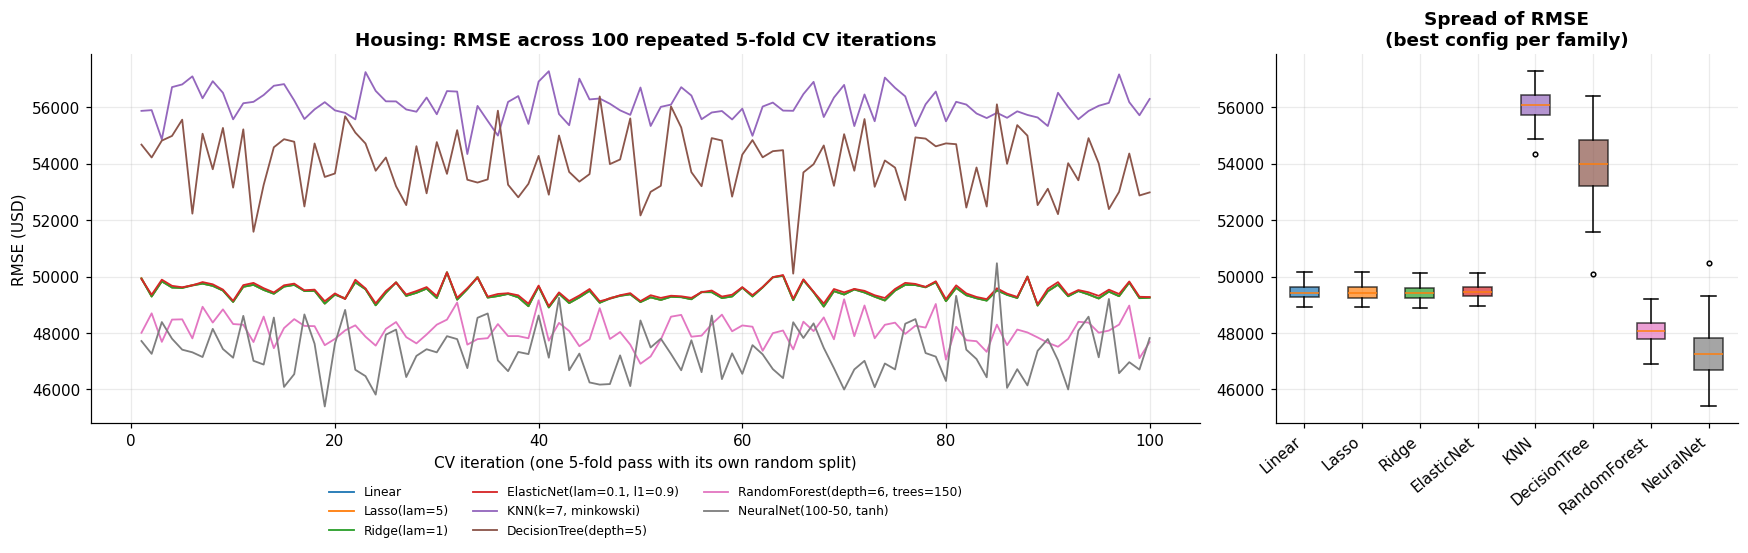

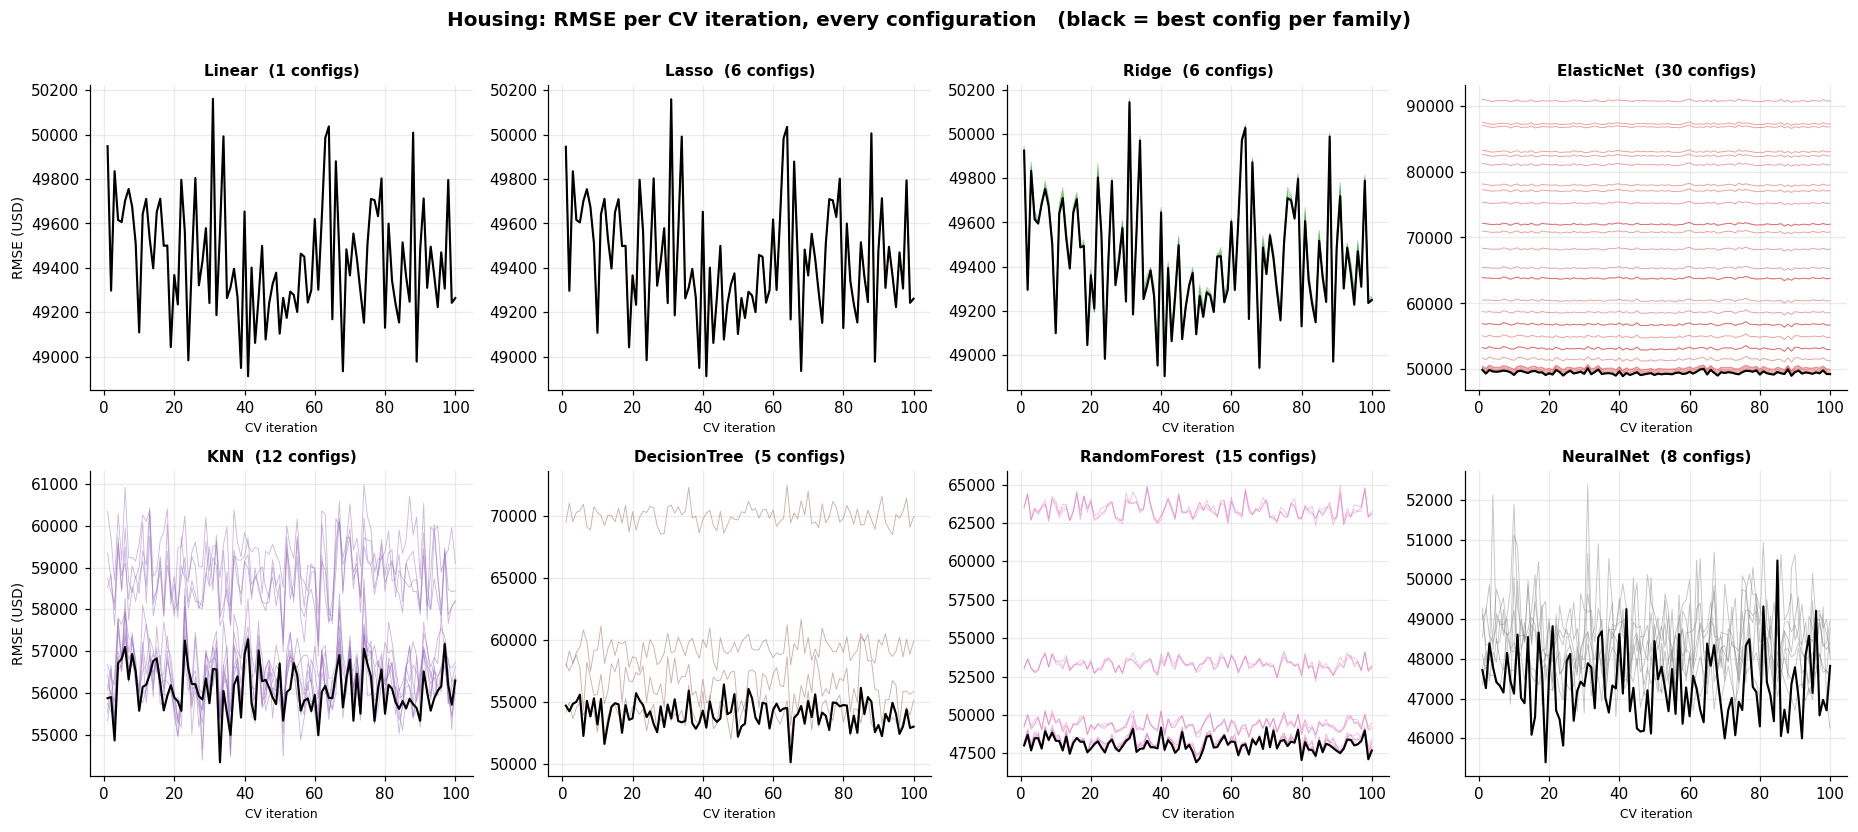

In [12]:
fig = plot_cv_family_best(cv_h, picks_h, 0, "RMSE", "Housing: RMSE across 100 repeated 5-fold CV iterations", "RMSE (USD)")
plt.show()

fig = plot_cv_small_multiples(cv_h, picks_h, 0, "Housing: RMSE per CV iteration, every configuration", "RMSE (USD)")
plt.show()

### 3.4 Which model won, and why

It depends on which yardstick you trust, and the disagreement is the interesting part. On the single prescribed test split, the linear models (each family at its best setting) are best and effectively identical (RMSE about $42,300, R² 0.83), the tuned neural network is close behind ($43,032), and the random forest ($47,057), KNN ($50,927) and decision tree ($54,332) trail. Across 100 repeated 5-fold CV runs, which is the evidence I trust most because no single lucky split can dominate it, the order changes: the neural network (100-50, tanh) has the lowest mean RMSE at $47,332, the random forest is next at $48,077, the linear models sit at about $49,440, and the decision tree ($54,001) and KNN ($56,089) are again at the bottom. For scale, always guessing the mean costs about $103,000 per house. My reading on this is that the fixed test split happens to be easier than average for linear models (their test RMSE is about $7,000 below their CV RMSE), which is exactly the kind of thing one split cannot reveal. The nonlinear models win in CV because the price surface really does have structure a straight line cannot hold: a location effect that multiplies the price rather than adding to it, and a slightly curved income effect. I built the data that way, so this explanation is partly by construction, and a real housing market would have to be checked on its own terms.

I would not give the victory to the neural network without a caveat, though. It's advantage over the random forest is about $750, which is smaller than the neural network's own iteration-to-iteration spread (standard deviation $909, with RMSE ranging from roughly $45,400 to $50,500 across the 100 repeats). The random forest is about twice as steady (standard deviation $472), and the linear models steadier still (about $265). The decision tree is the most erratic of all, with a range of more than $6,000 between its best and worst repeat. So my honest summary is: neural network and random forest are the two best models and nearly tied on average, the neural network has the better average and the random forest the better reliability, and if I had to ship one without further tuning I would pick the random forest. Finally, the lambda grid behaves very differently across the linear families. Lasso and Ridge barely move: every setting lands within about $30 of ordinary least squares (CV RMSE about $49,440), because lambda values up to 5 are tiny next to a target measured in dollars. Elastic Net is the exception and gets steadily worse as lambda rises and the L1 ratio falls, from $49,484 at lambda 0.1 with l1 ratio 0.9 to $90,730 at lambda 5 with l1 ratio 0.1. That is a scaling quirk, not a different kind of model: scikit-learn divides the squared-error loss by 2n in Elastic Net but not in Ridge, so the same lambda is a far heavier ridge penalty in Elastic Net. Its best setting is therefore simply the weakest one, and regularization of this kind does not help on this problem.

## 4. Task 2: Classification Analysis, Stroke Risk

**Goal:** Predict `At Risk (Binary)` from age and 15 symptom flags in `stroke_risk_dataset.csv`, using the same evaluation machinery as Task 1. Metrics saved for every model: Accuracy, Precision, Recall, F1-Score. F1 is the headline metric here, and everything gets ranked by it.

The assignment says to "use the same hyperparameters as Task 1", but Lasso, Ridge, Elastic Net and Linear Regression are regression models. My translation of instructions:

| Task 1 name | What I fit for the binary target |
|---|---|
| Lasso (lambda) | Logistic regression, L1 penalty, `C = 1/lambda` |
| Ridge (lambda) | Logistic regression, L2 penalty, `C = 1/lambda` |
| Elastic Net (lambda, l1 ratio) | Logistic regression, elastic-net penalty, `C = 1/lambda`, same l1 ratios |
| Linear Regression | Logistic regression with no penalty (the plain "standard" linear model for a 0/1 outcome) |
| KNN, Decision Tree, Random Forest, Neural Net | The classifier versions, same grids |

`C = 1/lambda` is the usual convention, but the penalty scaling in logistic regression is not identical to Lasso/Ridge regression, so the lambda values are comparable in spirit rather than in exact magnitude.

In [13]:
stroke = pd.read_csv(STROKE_CSV)
TARGET_S = "At Risk (Binary)"
LEAK_COL = "Stroke Risk (%)"

print(f"{stroke.shape[0]:,} rows x {stroke.shape[1]} columns   |   missing cells: {int(stroke.isna().sum().sum())}\n")
display(stroke.head())

balance = stroke[TARGET_S].value_counts().sort_index().rename({0: "not at risk (0)", 1: "at risk (1)"})
print("Class balance:")
display(pd.DataFrame({"rows": balance, "share": (balance / len(stroke)).round(3)}).T)

1,200 rows x 18 columns   |   missing cells: 0



,Age,Chest Pain,Shortness of Breath,Irregular Heartbeat,Fatigue & Weakness,Dizziness,Swelling (Edema),Pain in Neck/Jaw/Shoulder/Back,Excessive Sweating,Persistent Cough,Nausea/Vomiting,High Blood Pressure,Chest Discomfort (Activity),Cold Hands/Feet,Snoring/Sleep Apnea,Anxiety/Feeling of Doom,Stroke Risk (%),At Risk (Binary)
0,37,0,1,0,1,1,0,0,0,1,0,0,0,0,0,0,12.6,0
1,67,1,1,1,1,0,0,1,1,0,0,1,0,0,1,0,92.0,1
2,37,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,11.5,0
3,52,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0,22.9,0
4,69,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,33.7,0


Class balance:


At Risk (Binary),not at risk (0),at risk (1)
rows,821.000,379.000
share,0.684,0.316


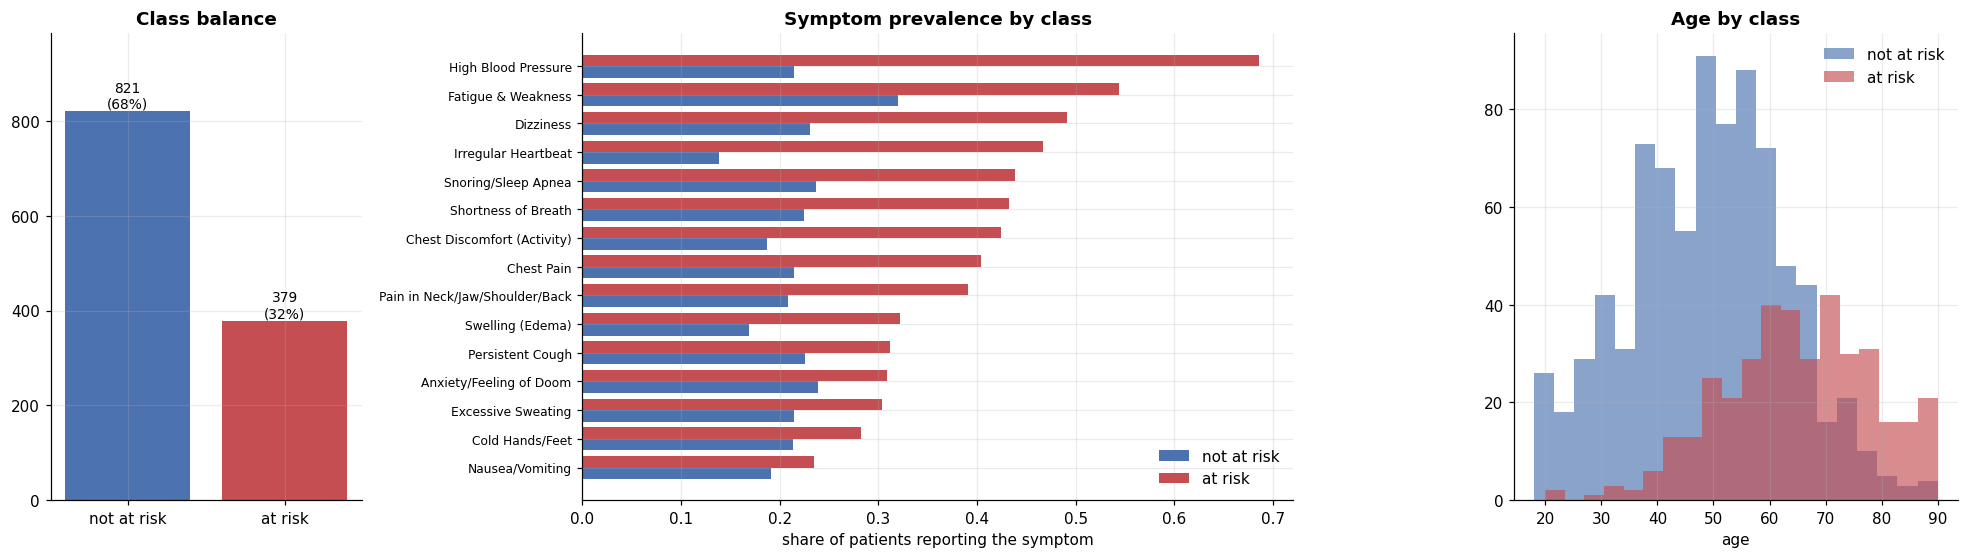

In [14]:
symptoms = [c for c in stroke.columns if c not in ("Age", LEAK_COL, TARGET_S)]
prev = stroke.groupby(TARGET_S)[symptoms].mean().T
prev.columns = ["not at risk", "at risk"]
prev = prev.sort_values("at risk")

fig, ax = plt.subplots(1, 3, figsize=(18, 5.2), gridspec_kw={"width_ratios": [0.7, 1.6, 1.0]})
ax[0].bar(["not at risk", "at risk"], balance.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(balance.values):
    ax[0].text(i, v, f"{v:,}\n({v / len(stroke):.0%})", ha="center", va="bottom", fontsize=9)
ax[0].set_ylim(0, balance.max() * 1.2); ax[0].set_title("Class balance")

yy = np.arange(len(prev))
ax[1].barh(yy - 0.2, prev["not at risk"], height=0.4, color="#4C72B0", label="not at risk")
ax[1].barh(yy + 0.2, prev["at risk"], height=0.4, color="#C44E52", label="at risk")
ax[1].set_yticks(yy); ax[1].set_yticklabels(prev.index, fontsize=8)
ax[1].set_xlabel("share of patients reporting the symptom"); ax[1].set_title("Symptom prevalence by class")
ax[1].legend(loc="lower right")

for lab, col in [("not at risk", "#4C72B0"), ("at risk", "#C44E52")]:
    ax[2].hist(stroke.loc[stroke[TARGET_S] == (lab == "at risk"), "Age"], bins=20, alpha=0.65, color=col, label=lab)
ax[2].set_title("Age by class"); ax[2].set_xlabel("age"); ax[2].legend()
fig.tight_layout()
plt.show()

### 4.1 A leakage trap hiding in the file

The file has 18 columns, but only 16 of them are legitimate predictors. `Stroke Risk (%)` is a continuous risk score, and `At Risk (Binary)` looks suspiciously like a threshold version of it. If that is true, using it as a predictor might be dishonest: a clinician would not have a precomputed stroke-risk percentage before deciding whether someone is at risk. I ran a simple check to catch this issue just in case. 

In [15]:
rule = (stroke[LEAK_COL] >= 50).astype(int)
print(f"Does 'Stroke Risk (%) >= 50' reproduce the target exactly?  match rate = {(rule == stroke[TARGET_S]).mean():.1%}")
print(f"Correlation of the leaky column with the target: {stroke[LEAK_COL].corr(stroke[TARGET_S]):.3f}\n")

# Demonstration only: same model, same split, with and without the leaky column
demo = []
for name, cols in [("WITH Stroke Risk (%)  [leaky, do not use]", [c for c in stroke.columns if c != TARGET_S]),
                   ("WITHOUT it (what I actually model)",         [c for c in stroke.columns if c not in (TARGET_S, LEAK_COL)])]:
    Xa, Xb, ya, yb = train_test_split(stroke[cols], stroke[TARGET_S], test_size=0.2, random_state=42, stratify=stroke[TARGET_S])
    pp = build_preprocessor(Xa)
    m = make_estimator("clf", "Ridge", {"lam": 1}).fit(pp.fit_transform(Xa), ya)
    demo.append({"features": name, **classification_metrics(yb, m.predict(pp.transform(Xb)))})
display(pd.DataFrame(demo).set_index("features").round(3))

Does 'Stroke Risk (%) >= 50' reproduce the target exactly?  match rate = 100.0%
Correlation of the leaky column with the target: 0.884



,Accuracy,Precision,Recall,F1
features,,,,
"WITH Stroke Risk (%) [leaky, do not use]",0.992,0.974,1.000,0.987
WITHOUT it (what I actually model),0.888,0.827,0.816,0.821


So the column is a near-perfect proxy for the label. I drop it from the predictors for everything that follows, which leaves **Age plus the 15 symptom flags (16 predictors)**. The honest accuracy is lower, and that is the number worth reporting.

### 4.2 Splitting the data

Again the prescribed calls, with stratification so the roughly 30% at-risk rate is preserved in every piece. The PDF text had a stray fragment (`Test_size=0.2, random_state=42)`) after the first call and a misplaced bracket in the second. I used the clearly intended versions.

In [16]:
X_stroke = stroke.drop(columns=[TARGET_S, LEAK_COL])
y_stroke = stroke[TARGET_S]

# --- the two splits, as prescribed (stratified) --------------------------------------------
X_stroke_train, X_stroke_test, y_stroke_train, y_stroke_test = train_test_split(
    X_stroke, y_stroke, test_size=0.2, random_state=42, stratify=y_stroke)

X_train, X_val, y_train, y_val = train_test_split(
    X_stroke_train, y_stroke_train, test_size=0.2, stratify=y_stroke_train, random_state=42)
# --------------------------------------------------------------------------------------------

print(pd.DataFrame({
    "rows":         [len(X_train), len(X_val), len(X_stroke_test), len(stroke)],
    "at-risk share": [y_train.mean(), y_val.mean(), y_stroke_test.mean(), y_stroke.mean()],
}, index=["train (fit)", "validation", "test (held out)", "total"]).round(3))
print(f"\nPredictors: {X_stroke.shape[1]}  ->  {', '.join(X_stroke.columns[:4])}, ...")

                 rows  at-risk share
train (fit)       768          0.315
validation        192          0.318
test (held out)   240          0.317
total            1200          0.316

Predictors: 16  ->  Age, Chest Pain, Shortness of Breath, Irregular Heartbeat, ...


In [17]:
t0 = time.time()
tt_s  = holdout_eval("clf", SPECS, X_stroke_train, y_stroke_train, {"test": (X_stroke_test, y_stroke_test)})
tvt_s = holdout_eval("clf", SPECS, X_train, y_train, {"val": (X_val, y_val), "test": (X_stroke_test, y_stroke_test)})
print(f"Train/Test and Train/Val/Test finished for {len(SPECS)} configurations in {time.time() - t0:.0f}s")

Train/Test and Train/Val/Test finished for 83 configurations in 7s


In [18]:
print(f"Running {N_REPEATS} x {N_FOLDS}-fold stratified cross-validation for {len(SPECS)} configurations ...")
cv_s, conv_cv_s, CV_SECONDS_S = run_cv("clf", SPECS, X_stroke_train, y_stroke_train, N_REPEATS)
print(f"\nDone in {CV_SECONDS_S / 60:.1f} minutes. Result array shape (repeats, configs, metrics) = {cv_s.shape}")

Running 100 x 5-fold stratified cross-validation for 83 configurations ...
   repeats   1-10  loaded from cache
   repeats  11-20  loaded from cache
   repeats  21-30  loaded from cache
   repeats  31-40  loaded from cache
   repeats  41-50  loaded from cache
   repeats  51-60  loaded from cache
   repeats  61-70  loaded from cache
   repeats  71-80  loaded from cache
   repeats  81-90  loaded from cache
   repeats  91-100 finished   (   119s elapsed)

Done in 19.9 minutes. Result array shape (repeats, configs, metrics) = (100, 83, 4)


### 4.3 Results

Same layout as Task 1: one table per metric, showing the best configuration in each family, where "best" now means **highest mean CV F1**. All 83 configurations and every metric are saved in `results_stroke_all_models.csv`.

In [19]:
wide_s = assemble("clf", tt_s, tvt_s, cv_s)
wide_s.to_csv("results_stroke_all_models.csv")
picks_s = best_per_family(wide_s, "clf")

for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    print(f"\n{metric} for the best configuration in each family")
    display(metric_view(wide_s, metric, picks_s).round(4))


Accuracy for the best configuration in each family


,Train/Test: test,Train/Val/Test: validation,Train/Val/Test: test,CV mean (x100),CV std dev
model,,,,,
Linear,0.8875,0.8802,0.8708,0.8822,0.0035
Lasso(lam=0.1),0.8875,0.8802,0.8708,0.8822,0.0035
Ridge(lam=0.1),0.8875,0.8802,0.8708,0.8821,0.0035
"ElasticNet(lam=0.1, l1=0.7)",0.8875,0.8802,0.8708,0.8822,0.0035
"KNN(k=5, euclidean)",0.8458,0.8698,0.8375,0.8282,0.0068
DecisionTree(depth=6),0.8500,0.8333,0.8208,0.8263,0.0107
"RandomForest(depth=6, trees=150)",0.8625,0.8698,0.8625,0.8719,0.0045
"NeuralNet(100, tanh)",0.8917,0.8802,0.8708,0.8681,0.0080



Precision for the best configuration in each family


,Train/Test: test,Train/Val/Test: validation,Train/Val/Test: test,CV mean (x100),CV std dev
model,,,,,
Linear,0.8267,0.8276,0.8000,0.8265,0.0067
Lasso(lam=0.1),0.8267,0.8276,0.8000,0.8268,0.0068
Ridge(lam=0.1),0.8267,0.8276,0.8000,0.8265,0.0068
"ElasticNet(lam=0.1, l1=0.7)",0.8267,0.8276,0.8000,0.8267,0.0067
"KNN(k=5, euclidean)",0.8980,0.8913,0.8776,0.8515,0.0152
DecisionTree(depth=6),0.7381,0.7302,0.6988,0.7480,0.0209
"RandomForest(depth=6, trees=150)",0.8116,0.8462,0.8209,0.8606,0.0093
"NeuralNet(100, tanh)",0.8049,0.7969,0.7778,0.7702,0.0170



Recall for the best configuration in each family


,Train/Test: test,Train/Val/Test: validation,Train/Val/Test: test,CV mean (x100),CV std dev
model,,,,,
Linear,0.8158,0.7869,0.7895,0.7966,0.0074
Lasso(lam=0.1),0.8158,0.7869,0.7895,0.7962,0.0076
Ridge(lam=0.1),0.8158,0.7869,0.7895,0.7962,0.0075
"ElasticNet(lam=0.1, l1=0.7)",0.8158,0.7869,0.7895,0.7963,0.0076
"KNN(k=5, euclidean)",0.5789,0.6721,0.5658,0.5533,0.0177
DecisionTree(depth=6),0.8158,0.7541,0.7632,0.6832,0.0265
"RandomForest(depth=6, trees=150)",0.7368,0.7213,0.7237,0.7105,0.0110
"NeuralNet(100, tanh)",0.8684,0.8361,0.8289,0.8369,0.0097



F1 for the best configuration in each family


,Train/Test: test,Train/Val/Test: validation,Train/Val/Test: test,CV mean (x100),CV std dev
model,,,,,
Linear,0.8212,0.8067,0.7947,0.8099,0.0058
Lasso(lam=0.1),0.8212,0.8067,0.7947,0.8099,0.0059
Ridge(lam=0.1),0.8212,0.8067,0.7947,0.8097,0.0059
"ElasticNet(lam=0.1, l1=0.7)",0.8212,0.8067,0.7947,0.8099,0.0058
"KNN(k=5, euclidean)",0.7040,0.7664,0.6880,0.6688,0.0154
DecisionTree(depth=6),0.7750,0.7419,0.7296,0.7118,0.0194
"RandomForest(depth=6, trees=150)",0.7724,0.7788,0.7692,0.7769,0.0085
"NeuralNet(100, tanh)",0.8354,0.8160,0.8025,0.8006,0.0098


### 4.4 F1-Score rankings

The first table ranks the eight families (each at its CV-best configuration). The second ranks every configuration across the whole grid. In both, the ranks come from three different evaluation methods, so a model that is only good under one of them stands out. The full 83-row ranking is saved to `f1_ranking_stroke.csv`.

In [ ]:
f1 = pd.DataFrame({
    "family":                     [s["family"] for s in SPECS],
    "F1 Train/Test (test)":       wide_s[(M_TT, "F1")].to_numpy(),
    "F1 Train/Val/Test (val)":    wide_s[(M_VAL, "F1")].to_numpy(),
    "F1 Train/Val/Test (test)":   wide_s[(M_TVT, "F1")].to_numpy(),
    "F1 CV mean":                 wide_s[(M_CV, "F1")].to_numpy(),
    "F1 CV std dev":              wide_s[(M_SD, "F1")].to_numpy(),
}, index=wide_s.index)

for new, col in [("rank: Train/Test", "F1 Train/Test (test)"),
                ("rank: Train/Val/Test (val)", "F1 Train/Val/Test (val)"),
                ("rank: CV", "F1 CV mean")]:
    f1[new] = f1[col].rank(ascending=False, method="min").astype(int)
f1["mean rank"] = f1[["rank: Train/Test", "rank: Train/Val/Test (val)", "rank: CV"]].mean(axis=1).round(1)
f1 = f1.sort_values(["rank: CV", "mean rank"])
f1.to_csv("f1_ranking_stroke.csv")

print("Families ranked by F1 (best configuration of each, chosen by CV):")
fam_rank = f1.loc[[SPECS[i]["label"] for i in picks_s]].sort_values("rank: CV")
display(fam_rank.drop(columns="family").round(4))

print("\nTop 20 configurations overall, ranked by mean CV F1:")
display(f1.head(20).drop(columns="family").round(4))

Families ranked by F1 (best configuration of each, chosen by CV):


,F1 Train/Test (test),F1 Train/Val/Test (val),F1 Train/Val/Test (test),F1 CV mean,F1 CV std dev,rank: Train/Test,rank: Train/Val/Test (val),rank: CV,mean rank
model,,,,,,,,,
Linear,0.8212,0.8067,0.7947,0.8099,0.0058,20,7,1,9.3
Lasso(lam=0.1),0.8212,0.8067,0.7947,0.8099,0.0059,20,7,2,9.7
"ElasticNet(lam=0.1, l1=0.7)",0.8212,0.8067,0.7947,0.8099,0.0058,20,7,3,10.0
Ridge(lam=0.1),0.8212,0.8067,0.7947,0.8097,0.0059,20,7,7,11.3
"NeuralNet(100, tanh)",0.8354,0.8160,0.8025,0.8006,0.0098,1,3,44,16.0
"RandomForest(depth=6, trees=150)",0.7724,0.7788,0.7692,0.7769,0.0085,54,54,48,52.0
DecisionTree(depth=6),0.7750,0.7419,0.7296,0.7118,0.0194,52,61,60,57.7
"KNN(k=5, euclidean)",0.7040,0.7664,0.6880,0.6688,0.0154,64,58,65,62.3



Top 20 configurations overall, ranked by mean CV F1:


,F1 Train/Test (test),F1 Train/Val/Test (val),F1 Train/Val/Test (test),F1 CV mean,F1 CV std dev,rank: Train/Test,rank: Train/Val/Test (val),rank: CV,mean rank
model,,,,,,,,,
Linear,0.8212,0.8067,0.7947,0.8099,0.0058,20,7,1,9.3
Lasso(lam=0.1),0.8212,0.8067,0.7947,0.8099,0.0059,20,7,2,9.7
"ElasticNet(lam=0.1, l1=0.7)",0.8212,0.8067,0.7947,0.8099,0.0058,20,7,3,10.0
"ElasticNet(lam=0.1, l1=0.9)",0.8212,0.8067,0.7947,0.8099,0.0059,20,7,4,10.3
"ElasticNet(lam=0.1, l1=0.5)",0.8212,0.8067,0.7947,0.8098,0.0058,20,7,5,10.7
"ElasticNet(lam=0.1, l1=0.3)",0.8212,0.8067,0.7947,0.8097,0.0058,20,7,6,11.0
Ridge(lam=0.1),0.8212,0.8067,0.7947,0.8097,0.0059,20,7,7,11.3
"ElasticNet(lam=0.1, l1=0.1)",0.8212,0.8067,0.7947,0.8097,0.0058,20,7,8,11.7
"ElasticNet(lam=1, l1=0.3)",0.8212,0.8067,0.7947,0.8096,0.0055,20,7,9,12.0


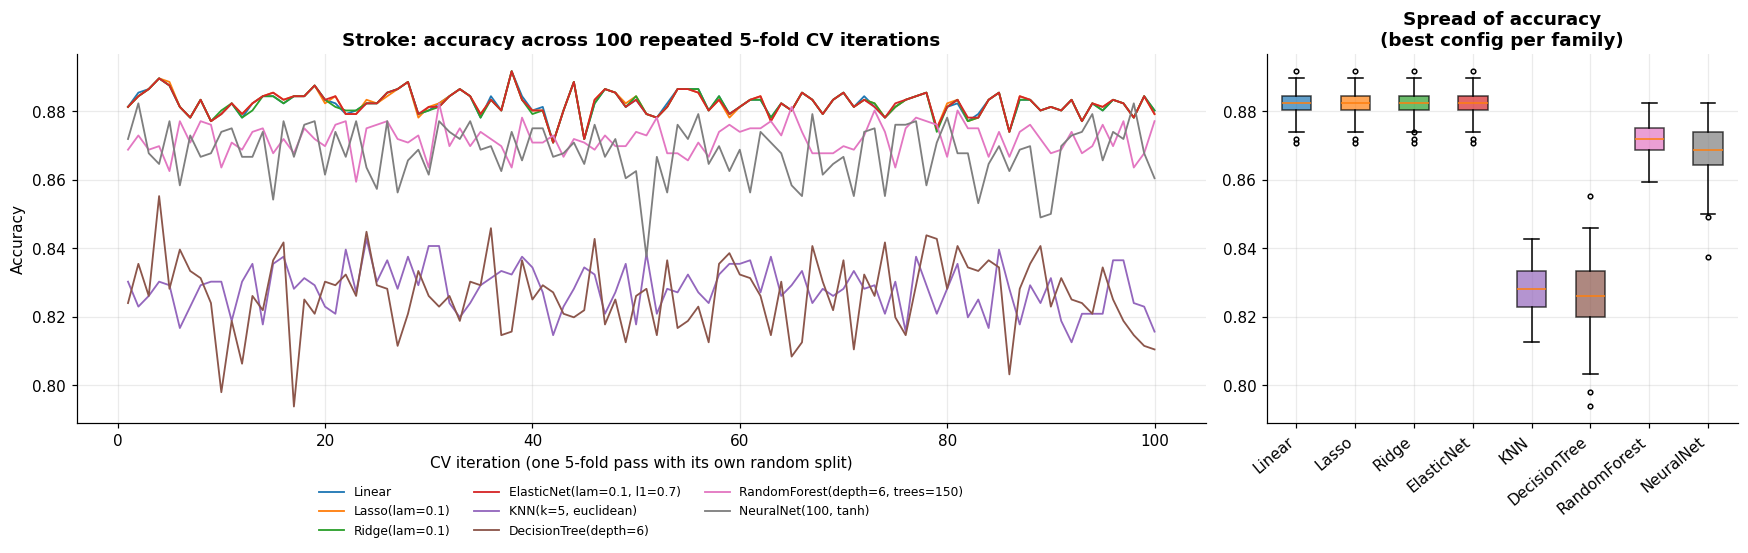

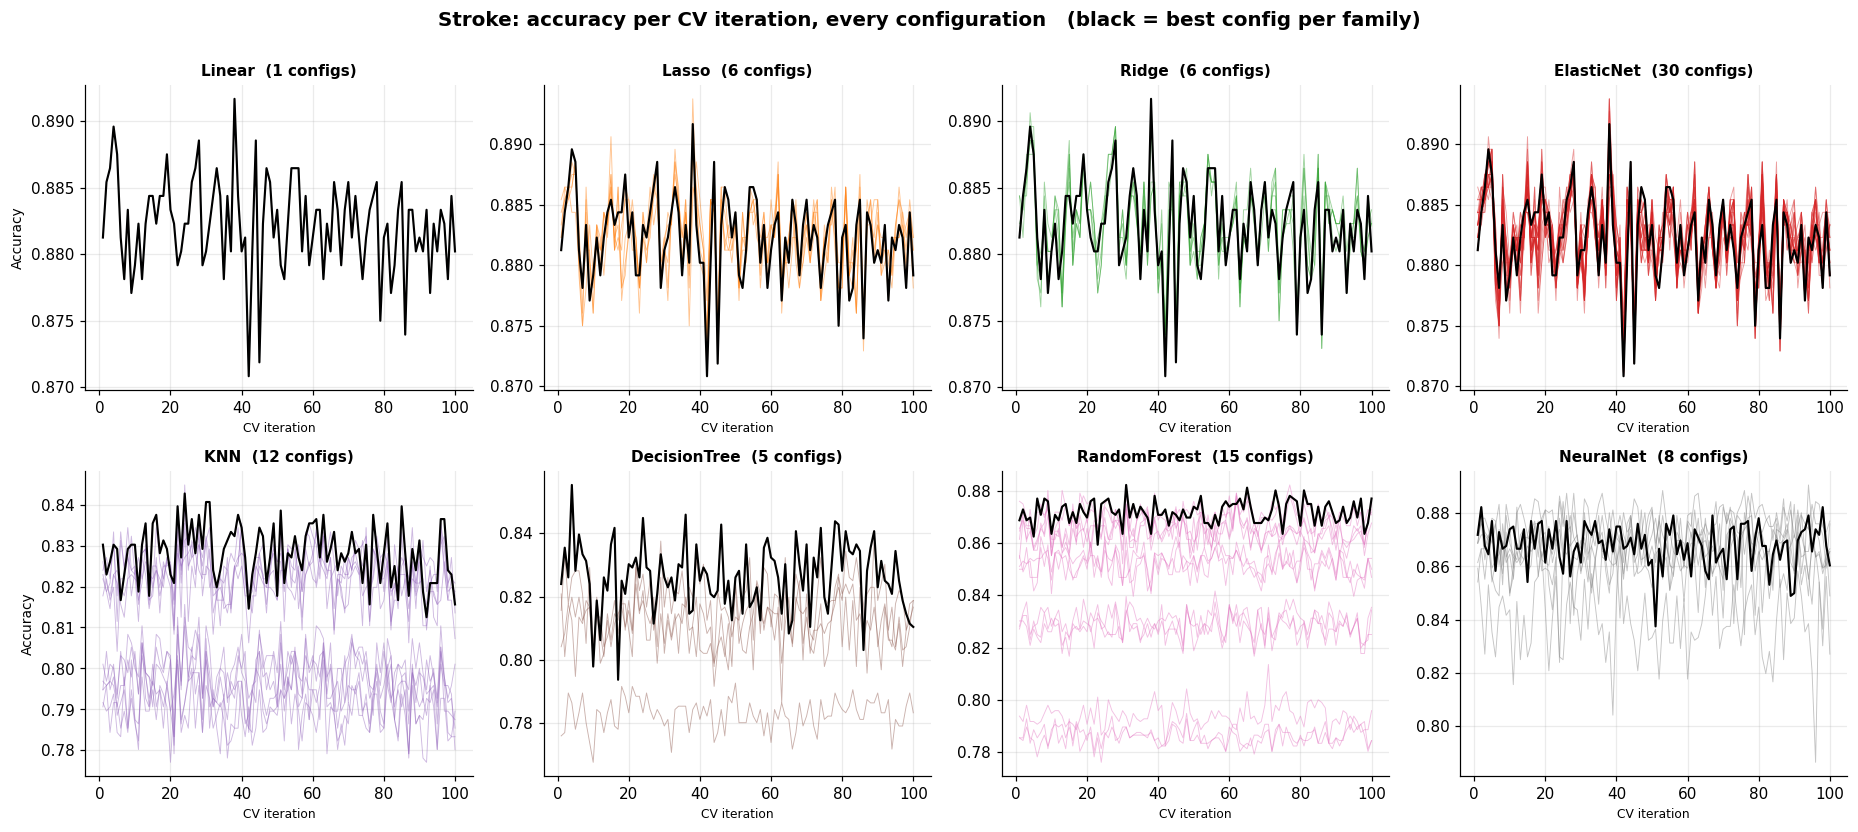

Accuracy stability across the 100 CV iterations (best config per family):


,mean accuracy,std dev,min,max
Linear,0.8822,0.0035,0.8708,0.8917
Lasso(lam=0.1),0.8822,0.0035,0.8708,0.8917
Ridge(lam=0.1),0.8821,0.0035,0.8708,0.8917
"ElasticNet(lam=0.1, l1=0.7)",0.8822,0.0035,0.8708,0.8917
"KNN(k=5, euclidean)",0.8282,0.0068,0.8125,0.8427
DecisionTree(depth=6),0.8263,0.0107,0.7938,0.8552
"RandomForest(depth=6, trees=150)",0.8719,0.0045,0.8594,0.8823
"NeuralNet(100, tanh)",0.8681,0.0080,0.8375,0.8823


In [21]:
fig = plot_cv_family_best(cv_s, picks_s, 0, "accuracy", "Stroke: accuracy across 100 repeated 5-fold CV iterations", "Accuracy")
plt.show()

fig = plot_cv_small_multiples(cv_s, picks_s, 0, "Stroke: accuracy per CV iteration, every configuration", "Accuracy")
plt.show()

stab_s = pd.DataFrame({
    "mean accuracy": [cv_s[:, i, 0].mean() for i in picks_s],
    "std dev":       [cv_s[:, i, 0].std(ddof=1) for i in picks_s],
    "min":           [cv_s[:, i, 0].min() for i in picks_s],
    "max":           [cv_s[:, i, 0].max() for i in picks_s],
}, index=[SPECS[i]["label"] for i in picks_s])
print("Accuracy stability across the 100 CV iterations (best config per family):")
display(stab_s.round(4))

### 4.5 ROC curves for the ten best models

"Best" is defined by mean CV F1 (so it uses training data only). The curves are then drawn on the held-out **test set**, from models fitted on the full training portion. The right-hand panel zooms into the top-left corner, because that is where ten good models become impossible to tell apart.

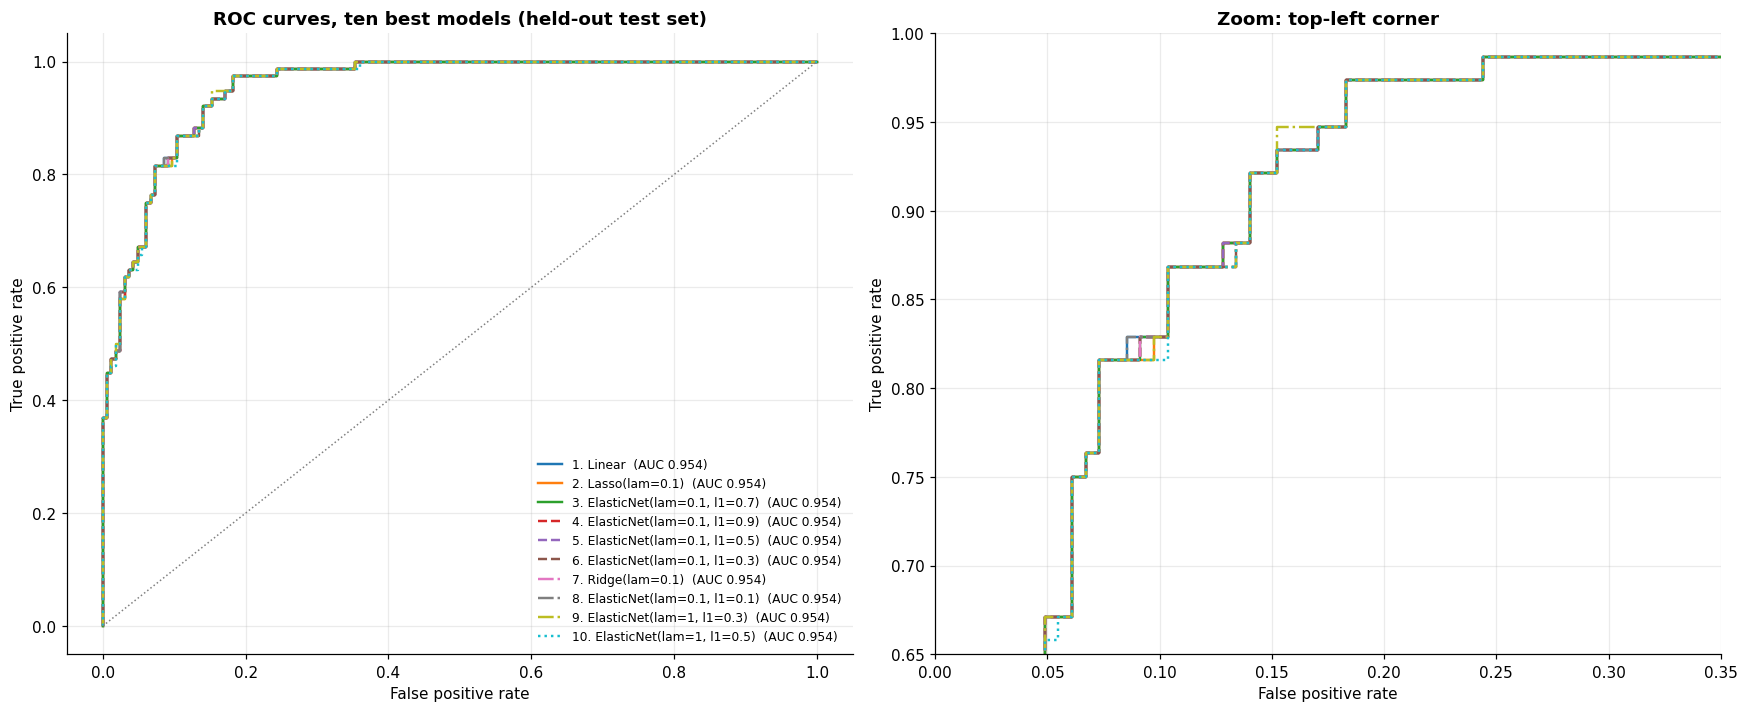

,model,CV F1 mean,test F1 (Train/Test),test AUC
CV F1 rank,,,,
1,Linear,0.8099,0.8212,0.9543
2,Lasso(lam=0.1),0.8099,0.8212,0.9541
3,"ElasticNet(lam=0.1, l1=0.7)",0.8099,0.8212,0.9543
4,"ElasticNet(lam=0.1, l1=0.9)",0.8099,0.8212,0.9542
5,"ElasticNet(lam=0.1, l1=0.5)",0.8098,0.8212,0.9543
6,"ElasticNet(lam=0.1, l1=0.3)",0.8097,0.8212,0.9542
7,Ridge(lam=0.1),0.8097,0.8212,0.9542
8,"ElasticNet(lam=0.1, l1=0.1)",0.8097,0.8212,0.9543
9,"ElasticNet(lam=1, l1=0.3)",0.8096,0.8212,0.9543


In [22]:
order = np.argsort(-wide_s[(M_CV, "F1")].to_numpy(), kind="stable")
top10 = [int(i) for i in order[:10]]
y_test_arr = np.asarray(y_stroke_test)

cmap = plt.cm.tab10.colors
styles = ["-", "--", "-.", ":"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6.6))
roc_rows = []
for rank, sid in enumerate(top10, 1):
    score = tt_s["scores"]["test"][sid]
    fpr, tpr, _ = roc_curve(y_test_arr, score)
    auc = roc_auc_score(y_test_arr, score)
    lab = f"{rank}. {SPECS[sid]['label']}  (AUC {auc:.3f})"
    for ax in (a1, a2):
        ax.plot(fpr, tpr, color=cmap[(rank - 1) % 10], ls=styles[(rank - 1) // 3 % 4], lw=1.6, label=lab if ax is a1 else None)
    roc_rows.append({"CV F1 rank": rank, "model": SPECS[sid]["label"], "CV F1 mean": wide_s.iloc[sid][(M_CV, "F1")],
                     "test F1 (Train/Test)": wide_s.iloc[sid][(M_TT, "F1")], "test AUC": auc})
a1.plot([0, 1], [0, 1], color="grey", ls=":", lw=1)
a1.set_xlabel("False positive rate"); a1.set_ylabel("True positive rate")
a1.set_title("ROC curves, ten best models (held-out test set)")
a1.legend(fontsize=8, loc="lower right")
a2.set_xlim(0, 0.35); a2.set_ylim(0.65, 1.0)
a2.set_xlabel("False positive rate"); a2.set_ylabel("True positive rate"); a2.set_title("Zoom: top-left corner")
fig.tight_layout()
plt.show()

display(pd.DataFrame(roc_rows).set_index("CV F1 rank").round(4))

### 4.6 KNN: which K and distance worked best?

In [ ]:
knn = [s for s in SPECS if s["family"] == "KNN"]
tbl = pd.DataFrame({
    "id":        [s["id"] for s in knn],
    "k":         [s["params"]["k"] for s in knn],
    "distance":  [s["params"]["metric"] for s in knn],
    "CV F1 mean":       [cv_s[:, s["id"], 3].mean() for s in knn],
    "CV F1 std dev":    [cv_s[:, s["id"], 3].std(ddof=1) for s in knn],
    "CV accuracy mean": [cv_s[:, s["id"], 0].mean() for s in knn],
    "Test F1 (Train/Test)": [wide_s.iloc[s["id"]][(M_TT, "F1")] for s in knn],
})
ranked = tbl.sort_values("CV F1 mean", ascending=False).reset_index(drop=True)
display(ranked.drop(columns="id").round(4))

print("Mean CV F1 by k and distance:")
display(tbl.pivot(index="k", columns="distance", values="CV F1 mean").round(4))
print("Mean CV accuracy by k and distance:")
display(tbl.pivot(index="k", columns="distance", values="CV accuracy mean").round(4))

best, second, worst = int(ranked.loc[0, "id"]), int(ranked.loc[1, "id"]), int(ranked.loc[len(ranked) - 1, "id"])
for name, other in [("runner-up", second), ("worst KNN config", worst)]:
    d = cv_s[:, best, 3] - cv_s[:, other, 3]
    print(f"Best ({SPECS[best]['label']}) minus {name} ({SPECS[other]['label']}): "
        f"mean F1 gap {d.mean():+.4f}, best was ahead in {np.mean(d > 0):.0%} of the {len(d)} CV iterations (paired)")

ties = {SPECS[s['id']]['label']: float(np.mean(tt_s['scores']['test'][s['id']] == 0.5)) for s in knn if s["params"]["k"] % 2 == 0}
print("\nShare of test patients where an even-k vote was an exact tie (probability = 0.5):")
display(pd.Series(ties, name="tie share").round(3).to_frame().T)

,k,distance,CV F1 mean,CV F1 std dev,CV accuracy mean,Test F1 (Train/Test)
0,5,euclidean,0.6688,0.0154,0.8282,0.7040
1,5,manhattan,0.6587,0.0145,0.8224,0.6929
2,5,minkowski,0.6573,0.0150,0.8233,0.6777
3,7,euclidean,0.6497,0.0137,0.8253,0.7040
4,7,manhattan,0.6475,0.0144,0.8230,0.6935
5,7,minkowski,0.6392,0.0129,0.8209,0.6984
6,6,manhattan,0.5697,0.0163,0.7999,0.6207
7,6,euclidean,0.5633,0.0169,0.7993,0.6325
8,6,minkowski,0.5565,0.0173,0.7974,0.6325
9,4,euclidean,0.5543,0.0159,0.7939,0.5841


Mean CV F1 by k and distance:


distance,euclidean,manhattan,minkowski
k,,,
4,0.5543,0.5443,0.5440
5,0.6688,0.6587,0.6573
6,0.5633,0.5697,0.5565
7,0.6497,0.6475,0.6392


Mean CV accuracy by k and distance:


distance,euclidean,manhattan,minkowski
k,,,
4,0.7939,0.7899,0.7902
5,0.8282,0.8224,0.8233
6,0.7993,0.7999,0.7974
7,0.8253,0.8230,0.8209


Best (KNN(k=5, euclidean)) minus runner-up (KNN(k=5, manhattan)): mean F1 gap +0.0101, best was ahead in 79% of the 100 CV iterations (paired)
Best (KNN(k=5, euclidean)) minus worst KNN config (KNN(k=4, minkowski)): mean F1 gap +0.1247, best was ahead in 100% of the 100 CV iterations (paired)

Share of test patients where an even-k vote was an exact tie (probability = 0.5):


,"KNN(k=4, euclidean)","KNN(k=4, manhattan)","KNN(k=4, minkowski)","KNN(k=6, euclidean)","KNN(k=6, manhattan)","KNN(k=6, minkowski)"
tie share,0.142,0.117,0.146,0.067,0.092,0.062


### 4.7 Interpretation

**Ranking by F1.** The top of the CV F1 ranking is a dead heat. The ten best configurations are all linear logistic models (plain logistic regression, Lasso, Ridge and Elastic Net with small lambdas), and their mean CV F1 scores run from 0.8096 to 0.8099, with test AUCs of 0.954 (0.9537 to 0.9543). Their ROC curves lie on top of each other in the plot, so the order *within* that group is noise, and the honest statement is "penalized or not, a logistic model is the best family here". That is not very surprising on reflection: I generated the label from a weighted sum of the symptoms plus noise, so a logistic model is close to the true model, and with 16 predictors and 768 training rows there is little overfitting for a penalty to fix. Behind them come the random forest (CV F1 0.777), the decision tree (0.712) and KNN (0.669).

The neural network is the cautionary tale. It has the best F1 of any model on the single Train/Test split (0.835, rank 1) and ranks third on the validation split, but its mean over 100 CV repeats is 0.801, which is only 44th in the grid. One favourable split made it look like the winner, and the repeated CV is what corrected that. The best linear configurations, by contrast, rank in the top 20 under all three evaluation methods.

**KNN: which K and distance?** K = 5 with Euclidean distance was best (CV F1 0.669, accuracy 0.828), followed by K = 5 Manhattan (0.659) and K = 5 Minkowski with p = 3 (0.657). Euclidean beat Manhattan by about 0.010 F1 on average and was ahead in 79 of the 100 paired CV iterations, so the edge is real but small. The distance metric matters far less than K. All odd values (5 and 7) scored above 0.639, while all even values (4 and 6) scored below 0.570. Even K can produce 50/50 votes (between 6% and 15% of test patients in my tie check), and ties fall to the lower class label, "not at risk". For a screening problem that is the wrong direction to be wrong, because it costs recall. K = 7 was slightly worse than K = 5, so the sweet spot of this grid is the smallest odd K. Even the best KNN trails the logistic models by about 0.14 F1. A plausible reason is that every symptom gets the same weight in a distance calculation, while the label depends on a few symptoms (high blood pressure, irregular heartbeat) much more than on others, but I did not test that explanation directly.

**A note on F1 for this problem.** F1 weights false alarms and missed cases equally. For stroke screening a missed case is usually the costlier error, so in a real deployment I would look at recall at a chosen precision, or move the decision threshold, rather than rely on F1 alone.

## 5. Notes and Discoveries

This is the running list of things I found while checking my own work: places the assignment can bite, decisions that change the numbers, and limits on what the results mean.

### Traps and typos in the assignment text
- The PDF code has typos (`train_ test_ split`, `y-housing_train`), and the stroke split snippets contain a stray fragment (`Test_size=0.2, random_state=42)`) and a misplaced bracket. 
- "Use the same hyperparameters" for a classification task includes Lasso, Ridge, Elastic Net and Linear Regression, which are not classifiers. I used the logistic-regression equivalents with `C = 1/lambda` (see Section 4). The lambda values are not exactly comparable between the two tasks.
- The Task 1 CV instruction is split across a line break ("Repeat this process 100 times / to analyze..."). I read it as 5-fold CV repeated 100 times, which is what the stability plots need.

### Decisions that change the numbers
- **Scaling can leak.** Standardizing the whole dataset before splitting is the tempting shortcut. Every scaler, imputer and encoder here is fitted inside the training rows of each split or fold (I verified it in Section 6: training columns have mean 0, test columns do not).
- **Minkowski vs Euclidean.** Minkowski distance with the default `p = 2` is mathematically Euclidean, so a naive grid compares two identical models. I set `p = 3` for the "minkowski" entry. The check cell in Section 6 shows the p=2 predictions are identical to Euclidean and the p=3 ones are not.
- **Even k and ties.** With k = 4 or 6, a KNN vote can split 50/50. The tie-breaker favours the lower class label (0, "not at risk"), which slightly biases those models toward predicting the majority class and costs recall. Section 4.6 measures how often ties occur.
- **The same lambda means different things in different scikit-learn models.** House values are around 10^5 dollars and the lambda grid stops at 5, which is tiny for Lasso and Ridge, so both land within about $30 of ordinary least squares (CV RMSE about $49,440). Elastic Net behaves differently: scikit-learn divides its squared-error loss by 2n but leaves Ridge's undivided, so the ridge part of Elastic Net is roughly n times stronger at the same lambda. Its CV RMSE rises from $49,484 (lambda 0.1, l1 ratio 0.9) to $90,730 (lambda 5, l1 ratio 0.1). This is a property of the assignment's grid and scikit-learn's parameterisation, not a bug, but it means a lambda comparison across Lasso, Ridge and Elastic Net is not apples to apples. For the logistic models in Task 2 the penalty is parameterised as `C = 1/lambda` on a summed loss, so that effect does not appear there.
- **Neural networks need a scaled target for regression.** Without it the network starts near zero and has to climb to values around 200,000, and the fit is awful for reasons that have nothing to do with the architecture. I wrap the regressor so the target is standardized internally and predictions are mapped back to dollars. I also use early stopping (`early_stopping=True`, patience 10, max 500 epochs), which keeps 4,000 network fits per task tractable and avoids mass convergence warnings.
- **Best model chosen by CV, not by the test set.** Reading the best row off a test-set table looks natural in the Train/Test method but is quietly optimistic. All "best" picks use CV on the training data; test numbers are only reported.
- **Random seeds.** Tree, forest and network models use a fixed `random_state`, so across the 100 CV iterations the only thing that changes is which rows land in which fold. The spread in the plots is therefore *partition sensitivity*, not run-to-run noise from the learners.

### Data wrinkles
- **Leakage column.** `Stroke Risk (%)` reproduces the label with a threshold at 50. It is excluded from the predictors (Section 4.1 quantifies the inflation).
- **Top-coded target.** A few percent of house values sit exactly at 500,001. These are censored values, so RMSE understates the error on the most expensive homes, and no linear model can extrapolate past the cap.
- **Missing values.** `total_bedrooms` has a handful of blanks. They are median-imputed using training rows only.
- **Collinearity.** Rooms, bedrooms, population and households carry overlapping information (VIF table in Section 3). Fine for prediction, not for interpreting single coefficients.
- **Class imbalance.** About 30% of patients are labelled at risk. Accuracy alone would flatter a model that leans toward the majority class, which is why F1 (and recall) are the headline numbers. Precision, recall and F1 are computed with `zero_division=0`, so a model that never predicts "at risk" scores 0 instead of crashing.
- **Synthetic data.** Both files are generated. The patterns in them are the ones I put there, so the results show how the methods behave, not how housing markets or stroke screening behave.

### Statistical caveats worth stating plainly
- The 100 CV iterations all reshuffle the **same** training rows. They are not 100 independent samples of the world, so the standard deviations across iterations understate the real uncertainty about how a model will do on new data. They are good for ranking stability, not for confidence intervals.
- Differences of a fraction of a percentage point between neighboring configurations (for example between two KNN settings) are inside that noise. I use paired comparisons across iterations where it matters.
- Test sets are small (200 and 240 rows), so single-split numbers can move noticeably with the seed. This showed up in the results: the housing test split favoured the linear models by about $7,000 of RMSE compared with their CV average, and in the stroke task the neural network was first on one split but 44th by CV F1.

### Fail points I checked
- **Missing CSVs:** the notebook regenerates them and carries on (tested by deleting both files and running from a clean folder).
- **scikit-learn API drift:** `LogisticRegression(penalty=...)` is deprecated in 1.8 in favour of `l1_ratio`. A small wrapper handles both. The notebook requires scikit-learn 1.2 or newer (`OneHotEncoder(sparse_output=...)`) and asserts it up front.
- **Variable clobbering:** `X_train`/`X_val` are reused between tasks. Functions take explicit arguments, so nothing depends on the globals.
- **Parallelism:** the CV runs through joblib. `N_JOBS = -1` uses all cores; with one core it simply runs serially.
- **Convergence:** warnings are counted rather than silenced (table at the end of this section). The only family that ever tripped one was Lasso on the housing data (599 of its 3,000 CV fits, 2 in Train/Val/Test) and it hit the 10,000-iteration cap before reaching the default tolerance. Its CV RMSE is within a few dollars of Ridge and plain least squares, so the effect on the conclusions is negligible, but I did not tune it further. The logistic models, networks (which stop early) and everything else converged cleanly.

In [24]:
def conv_by_family(*arrays_and_names):
    out = {}
    for name, arr in arrays_and_names:
        out[name] = pd.Series(arr, index=[s["family"] for s in SPECS]).groupby(level=0, sort=False).sum().reindex(FAMILIES)
    return pd.DataFrame(out).astype(int)

print("Housing: ConvergenceWarnings raised while fitting (summed per family)")
display(conv_by_family(("Train/Test", tt_h["conv"]), ("Train/Val/Test", tvt_h["conv"]), ("CV (all folds x repeats)", conv_cv_h)).T)
print("Stroke: ConvergenceWarnings raised while fitting (summed per family)")
display(conv_by_family(("Train/Test", tt_s["conv"]), ("Train/Val/Test", tvt_s["conv"]), ("CV (all folds x repeats)", conv_cv_s)).T)

Housing: ConvergenceWarnings raised while fitting (summed per family)


,Linear,Lasso,Ridge,ElasticNet,KNN,DecisionTree,RandomForest,NeuralNet
Train/Test,0,0,0,0,0,0,0,0
Train/Val/Test,0,2,0,0,0,0,0,0
CV (all folds x repeats),0,599,0,0,0,0,0,0


Stroke: ConvergenceWarnings raised while fitting (summed per family)


,Linear,Lasso,Ridge,ElasticNet,KNN,DecisionTree,RandomForest,NeuralNet
Train/Test,0,0,0,0,0,0,0,0
Train/Val/Test,0,0,0,0,0,0,0,0
CV (all folds x repeats),0,0,0,0,0,0,0,0


## 6. Automated sanity checks, environment, and a closing reflection

These checks run every time the notebook runs. If any of them fails the cell stops with an error, which is what I want from a notebook someone else is going to execute.
There is a lot of data and I wanted to add a stop gate just in case things go wrong.

In [ ]:
checks = []
def check(name, cond, detail=""):
    checks.append({"check": name, "passed": bool(cond), "detail": detail})

# --- files ---------------------------------------------------------------------------------
check("housing.csv and stroke_risk_dataset.csv exist", os.path.exists(HOUSING_CSV) and os.path.exists(STROKE_CSV))
check("housing target and stroke label columns present", TARGET_H in housing.columns and TARGET_S in stroke.columns)

# --- splits: sizes, no overlap, stratification ---------------------------------------------
Xa, Xb, ya, yb = train_test_split(X_housing_train, y_housing_train, test_size=0.2, random_state=42)
hs, ht, hv = set(Xa.index), set(X_housing_test.index), set(Xb.index)
check("housing: train/val/test are disjoint and cover every row",
      not (hs & ht) and not (hs & hv) and not (hv & ht) and len(hs | ht | hv) == len(housing),
      f"{len(hs)}/{len(hv)}/{len(ht)}")
ss, st, sv = set(X_train.index), set(X_stroke_test.index), set(X_val.index)
check("stroke: train/val/test are disjoint and cover every row",
      not (ss & st) and not (ss & sv) and not (sv & st) and len(ss | st | sv) == len(stroke),
      f"{len(ss)}/{len(sv)}/{len(st)}")
rates = [y_train.mean(), y_val.mean(), y_stroke_test.mean()]
check("stroke: at-risk rate is within 1 point across train/val/test (stratification worked)",
      max(rates) - min(rates) < 0.01, f"{min(rates):.3f} to {max(rates):.3f}")

# --- preprocessing does not leak -------------------------------------------------------------
check("scaler: training columns have mean ~0 and std ~1", np.abs(Z_tr.mean(0)).max() < 1e-9 and np.allclose(Z_tr.std(0), 1.0))
check("scaler: held-out columns are NOT exactly centred (no test info used)", np.abs(Z_te.mean(0)).max() > 1e-6)

# --- grid and result arrays --------------------------------------------------------------------
fam_counts = pd.Series([s["family"] for s in SPECS]).value_counts().to_dict()
expected = {"Linear": 1, "Lasso": 6, "Ridge": 6, "ElasticNet": 30, "KNN": 12, "DecisionTree": 5, "RandomForest": 15, "NeuralNet": 8}
check("grid has exactly the configurations the assignment lists (83)", fam_counts == expected and len(SPECS) == 83)
check("housing CV array has shape (repeats, 83, 4) and is finite", cv_h.shape == (N_REPEATS, 83, 4) and np.isfinite(cv_h).all())
check("stroke CV array has shape (repeats, 83, 4) and is finite", cv_s.shape == (N_REPEATS, 83, 4) and np.isfinite(cv_s).all())
check("all single-split metrics are finite", all(np.isfinite(df[METRIC_NAMES[t]].to_numpy()).all()
      for t, r in [("reg", tt_h), ("reg", tvt_h), ("clf", tt_s), ("clf", tvt_s)] for df in r["metrics"].values()))
check("CV was run the number of times the assignment asks for (100) unless QUICK_RUN", N_REPEATS == 100 or QUICK_RUN)

# --- reproducibility: refit a handful of models and compare with the stored numbers -------------
subset = [s for s in SPECS if s["label"] in ("Linear", "Ridge(lam=3)", "KNN(k=5, manhattan)", "DecisionTree(depth=4)", "RandomForest(depth=3, trees=50)")]
subset = [dict(s, id=i) for i, s in enumerate(subset)]
again = holdout_eval("reg", subset, X_housing_train, y_housing_train, {"test": (X_housing_test, y_housing_test)})["metrics"]["test"]
stored = tt_h["metrics"]["test"].set_index("model").loc[again["model"], "RMSE"].to_numpy()
check("re-running Train/Test on 5 housing models reproduces the stored RMSE exactly", np.allclose(again["RMSE"].to_numpy(), stored, rtol=0, atol=1e-6))

# --- the Minkowski trap --------------------------------------------------------------------------
Zh_tr = build_preprocessor(X_housing_train).fit(X_housing_train)
A_tr, A_te = Zh_tr.transform(X_housing_train), Zh_tr.transform(X_housing_test)
pe = KNeighborsRegressor(n_neighbors=5, metric="euclidean").fit(A_tr, y_housing_train).predict(A_te)
p2 = KNeighborsRegressor(n_neighbors=5, metric="minkowski", p=2).fit(A_tr, y_housing_train).predict(A_te)
p3 = KNeighborsRegressor(n_neighbors=5, metric="minkowski", p=MINKOWSKI_P).fit(A_tr, y_housing_train).predict(A_te)
check("Minkowski with p=2 is identical to Euclidean (why the grid uses p=3)", np.allclose(pe, p2))
check(f"Minkowski with p={MINKOWSKI_P} is genuinely different from Euclidean", not np.allclose(pe, p3))

# --- leakage column and sanity versus baselines --------------------------------------------------
check("stroke: 'Stroke Risk (%) >= 50' reproduces the label (leak confirmed and column excluded)",
      (rule == stroke[TARGET_S]).all() and LEAK_COL not in X_stroke.columns)
base_f1 = 2 * y_stroke_test.mean() / (1 + y_stroke_test.mean())      # F1 of "predict everyone at risk"
check("best stroke model beats the trivial all-positive F1 baseline",
      wide_s[(M_CV, "F1")].max() > base_f1, f"{wide_s[(M_CV, 'F1')].max():.3f} vs {base_f1:.3f}")
check("best housing model beats predicting the training mean (positive test R2)",
      wide_h[(M_TT, "R2")].max() > 0, f"best test R2 = {wide_h[(M_TT, 'R2')].max():.3f}")

report = pd.DataFrame(checks)
display(report)
assert report["passed"].all(), "At least one sanity check failed, see table above"
print(f"\nAll {len(report)} checks passed.")

,check,passed,detail
0,housing.csv and stroke_risk_dataset.csv exist,True,
1,housing target and stroke label columns present,True,
2,housing: train/val/test are disjoint and cover every row,True,640/160/200
3,stroke: train/val/test are disjoint and cover every row,True,768/192/240
4,stroke: at-risk rate is within 1 point across train/val/...,True,0.315 to 0.318
5,scaler: training columns have mean ~0 and std ~1,True,
6,scaler: held-out columns are NOT exactly centred (no tes...,True,
7,grid has exactly the configurations the assignment lists...,True,
8,"housing CV array has shape (repeats, 83, 4) and is finite",True,
9,"stroke CV array has shape (repeats, 83, 4) and is finite",True,



All 18 checks passed.


In [26]:
print("Compute time for the repeated cross-validation (this machine, N_JOBS=%s):" % N_JOBS)
print(f"   housing: {CV_SECONDS_H / 60:5.1f} min      stroke: {CV_SECONDS_S / 60:5.1f} min")
print(f"\nPython {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print("\nFiles this notebook reads or writes in the working folder:")
for f in [HOUSING_CSV, STROKE_CSV, "results_housing_all_models.csv", "results_stroke_all_models.csv", "f1_ranking_stroke.csv"]:
    print(f"   {f:<34} {os.path.getsize(f) / 1024:8.1f} KB")

Compute time for the repeated cross-validation (this machine, N_JOBS=-1):
   housing:  26.0 min      stroke:  19.9 min

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | scikit-learn 1.8.0

Files this notebook reads or writes in the working folder:
   housing.csv                            57.2 KB
   stroke_risk_dataset.csv                46.9 KB
   results_housing_all_models.csv         32.6 KB
   results_stroke_all_models.csv          32.4 KB
   f1_ranking_stroke.csv                  11.7 KB


### Closing reflection

I am a bit puzzled and keep returning  back to is how often a single split lied to me! The housing test split flattered the linear models by about $7,000 of RMSE, and in the stroke task a neural network took first place on one split and 44th place across 100 CV repeats. If I had stopped after the train/test numbers my write-up would have named the wrong winner twice. The second lesson was the leakage column: a 99% accurate model turned into an 89% accurate one the moment I removed a feature that a real clinician would not have. That drop is the real number.

Some limits I want to be upfront about. Both datasets are synthetic, so I know the structure the models were hunting for, and the result that logistic regression wins the stroke task is partly a result of how I generated the label. The 100 CV repeats reshuffle the same training rows, so they show how stable a ranking is, not how a model will do on new people. I also did not run formal paired significance tests across all 83 configurations (only for the KNN comparison), and the top of the stroke ranking is too close to separate anyway.

If I kept going I would have (1) repeat the study on the real public versions of these two datasets, (2) use nested cross-validation so hyperparameters and performance are estimated on separate data, (3) tune the decision threshold for recall in the stroke task, since in screening the cost of missing a patient and the cost of a false alarm are not equal, and (4) check calibration, because a clinician reading a risk score needs it to mean what it says. In a human-centered setting I would also weigh the fact that the best stroke models here are plain logistic regressions, whose coefficients a person can read and question, over a neural network that was never clearly better.

*NOTE:  Provenance of the saved outputs: the outputs stored in this notebook come from one scripted full run with `N_REPEATS = 100`. Because that run took a while, it was executed in segments with the resume cache switched on, so some progress lines read "loaded from cache"; the compute times shown are the original ones. A fresh `Restart & Run All` will reproduce the same tables (the seeds are fixed).*